# Objectif 
L'objectif est d'analyser les conditions de propagation permettant d'expliquer la propagation observée à l'OBS 7 au cours de la portion 1. 

Date de création : 14/10/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


In [3]:
ROOT_IMG_PROPAGATION = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\acouplane\img\portion1\propagation"

# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [4]:
portion_id = 1
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB ...
│   │           tir_src_lat            (src_datetime) float64 3kB ...
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB ...
│   │           tir_src_lat            (src_datetime) float64 2kB ...
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Ouest/Est
│   │           section_id:               1
│   ├── Group: /position/oe2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

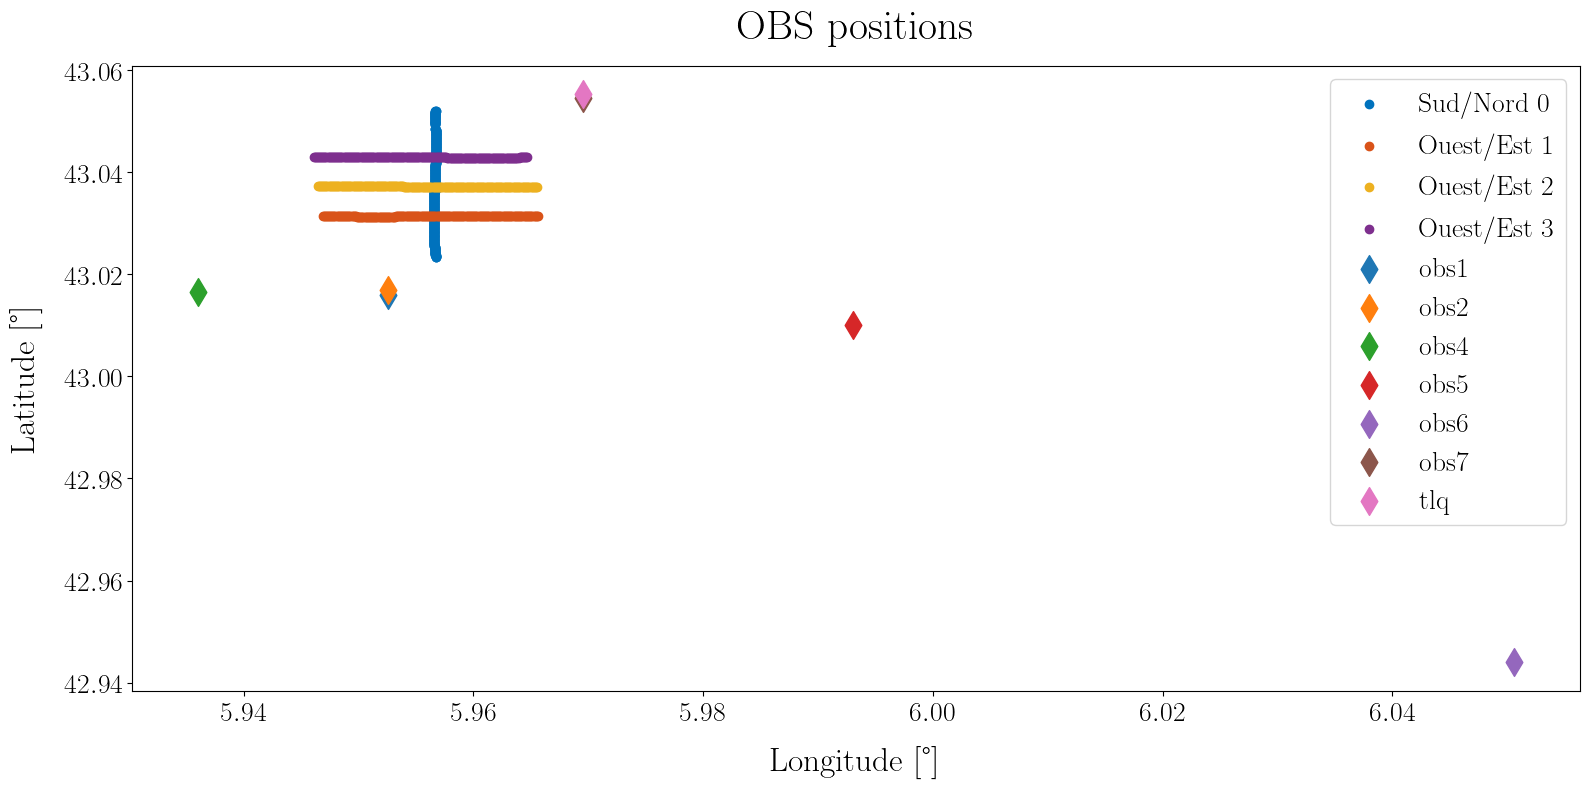

In [5]:
plot_portion_tir_pos(portion_tree=portion)

# Signaux d'intérêt 

Tracer des signaux étudiés. 

In [6]:
c0 = 1508       # equivalent celerity 
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s
    ds_pos_section.tps_propagation_s.attrs = {
        "units": "s",
        "long_name": "Propagation time",
    }

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

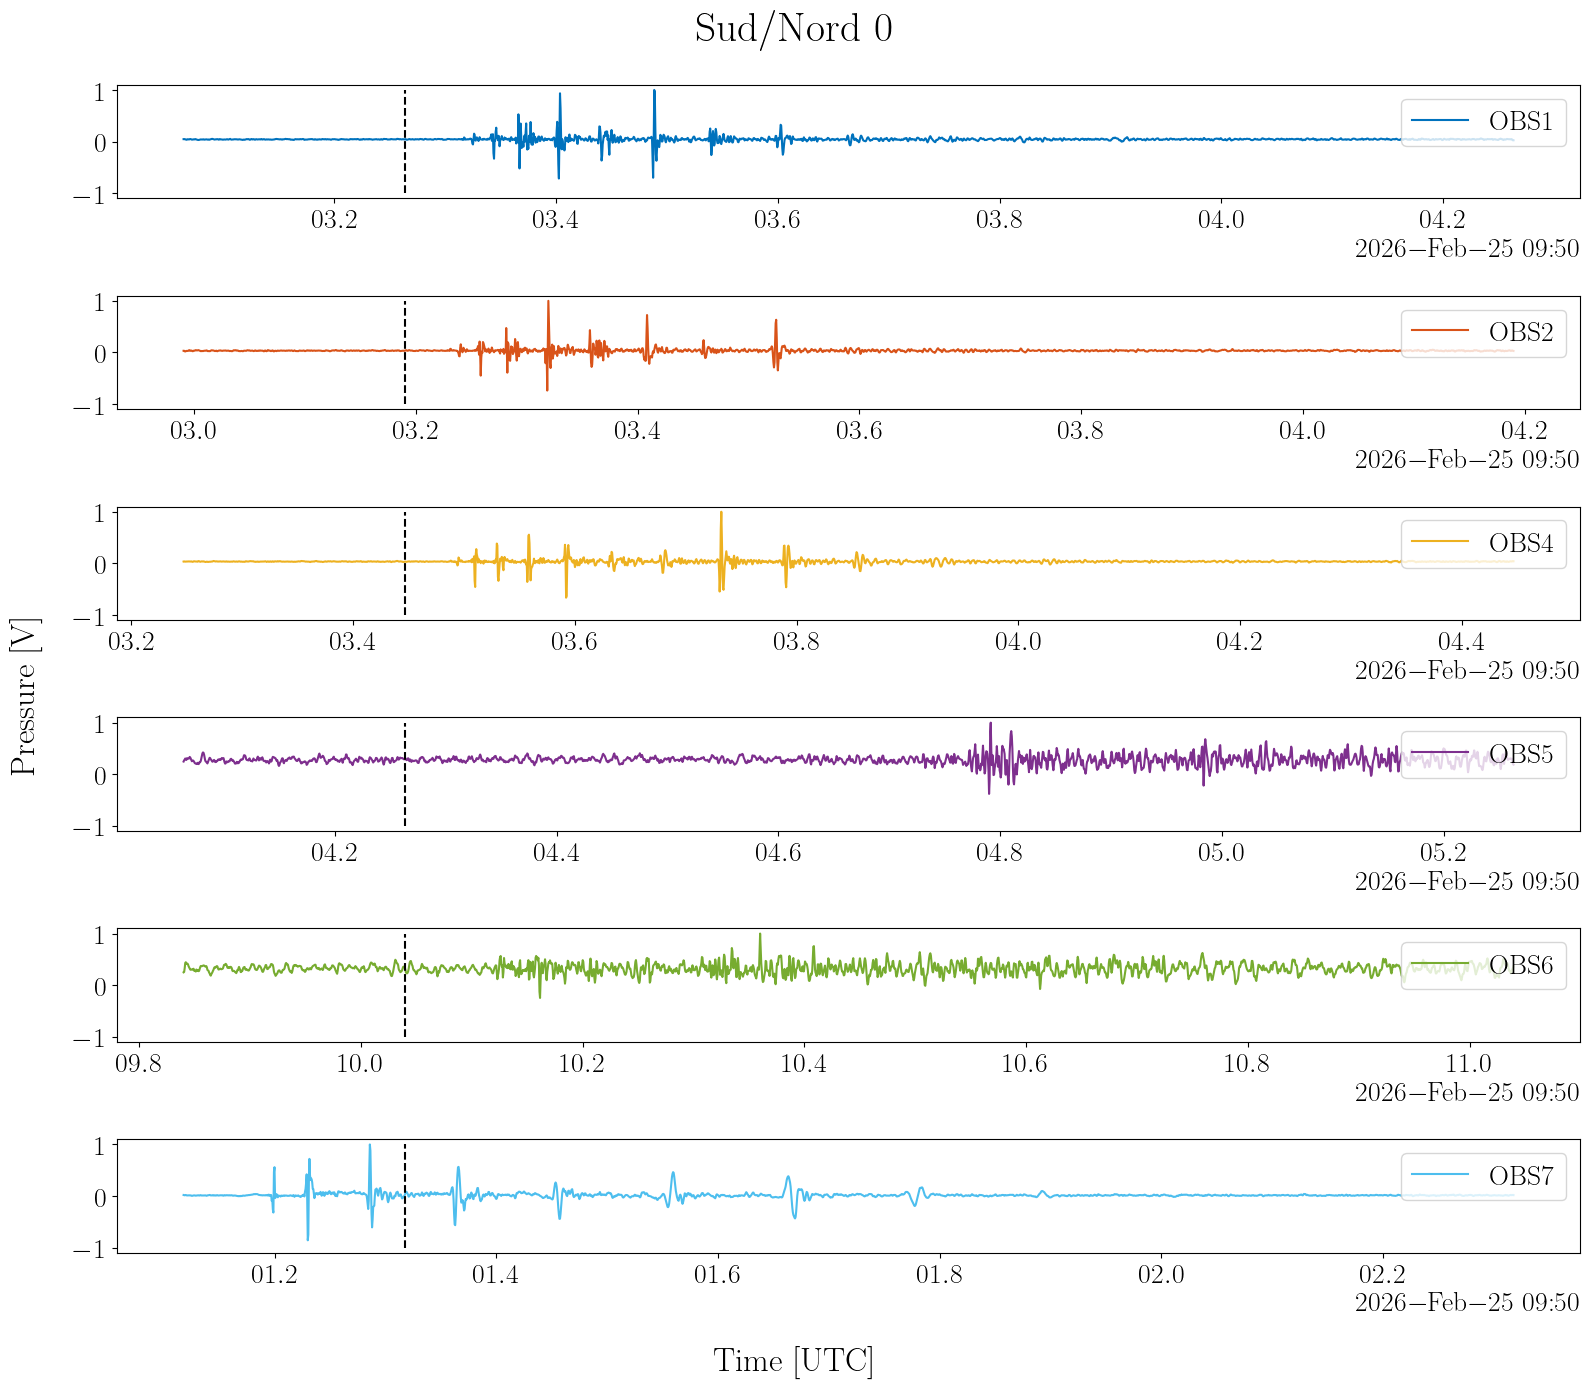

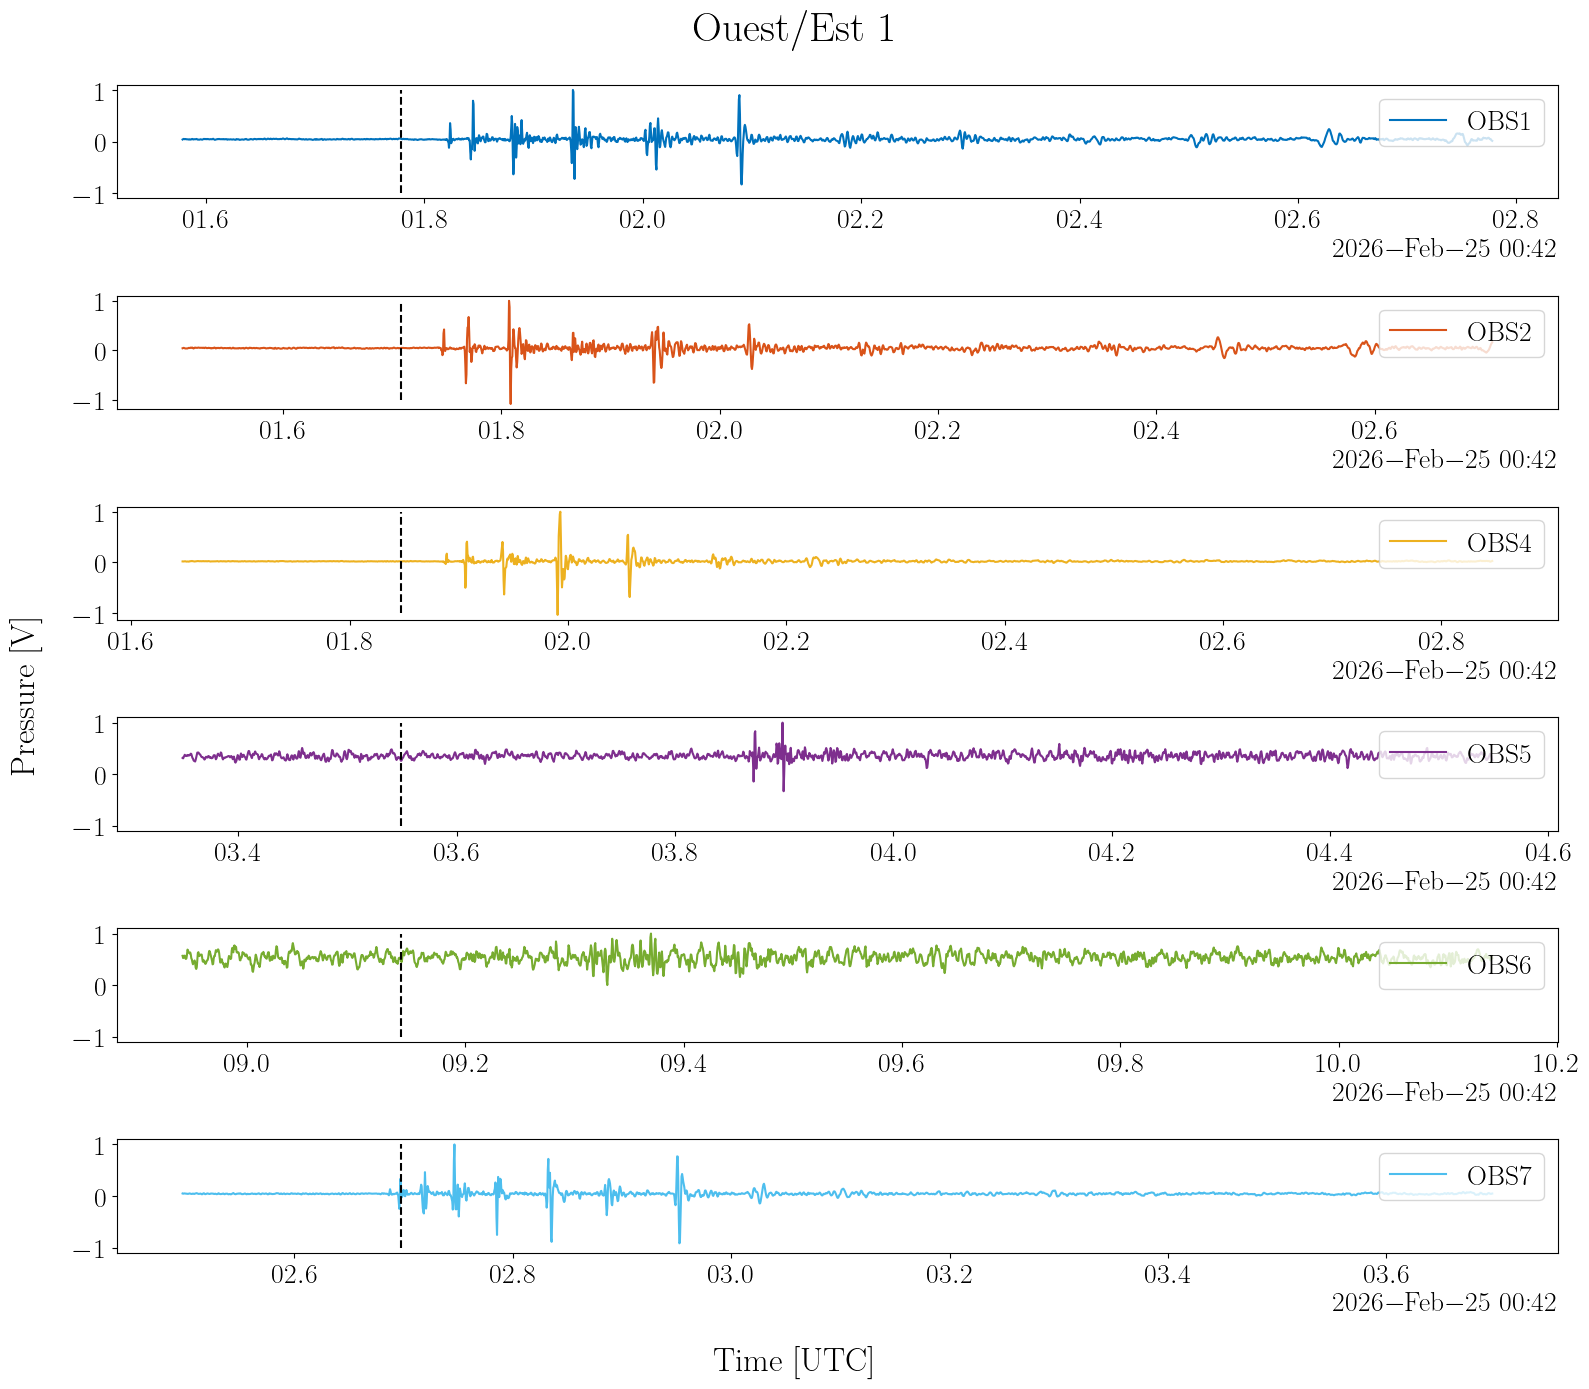

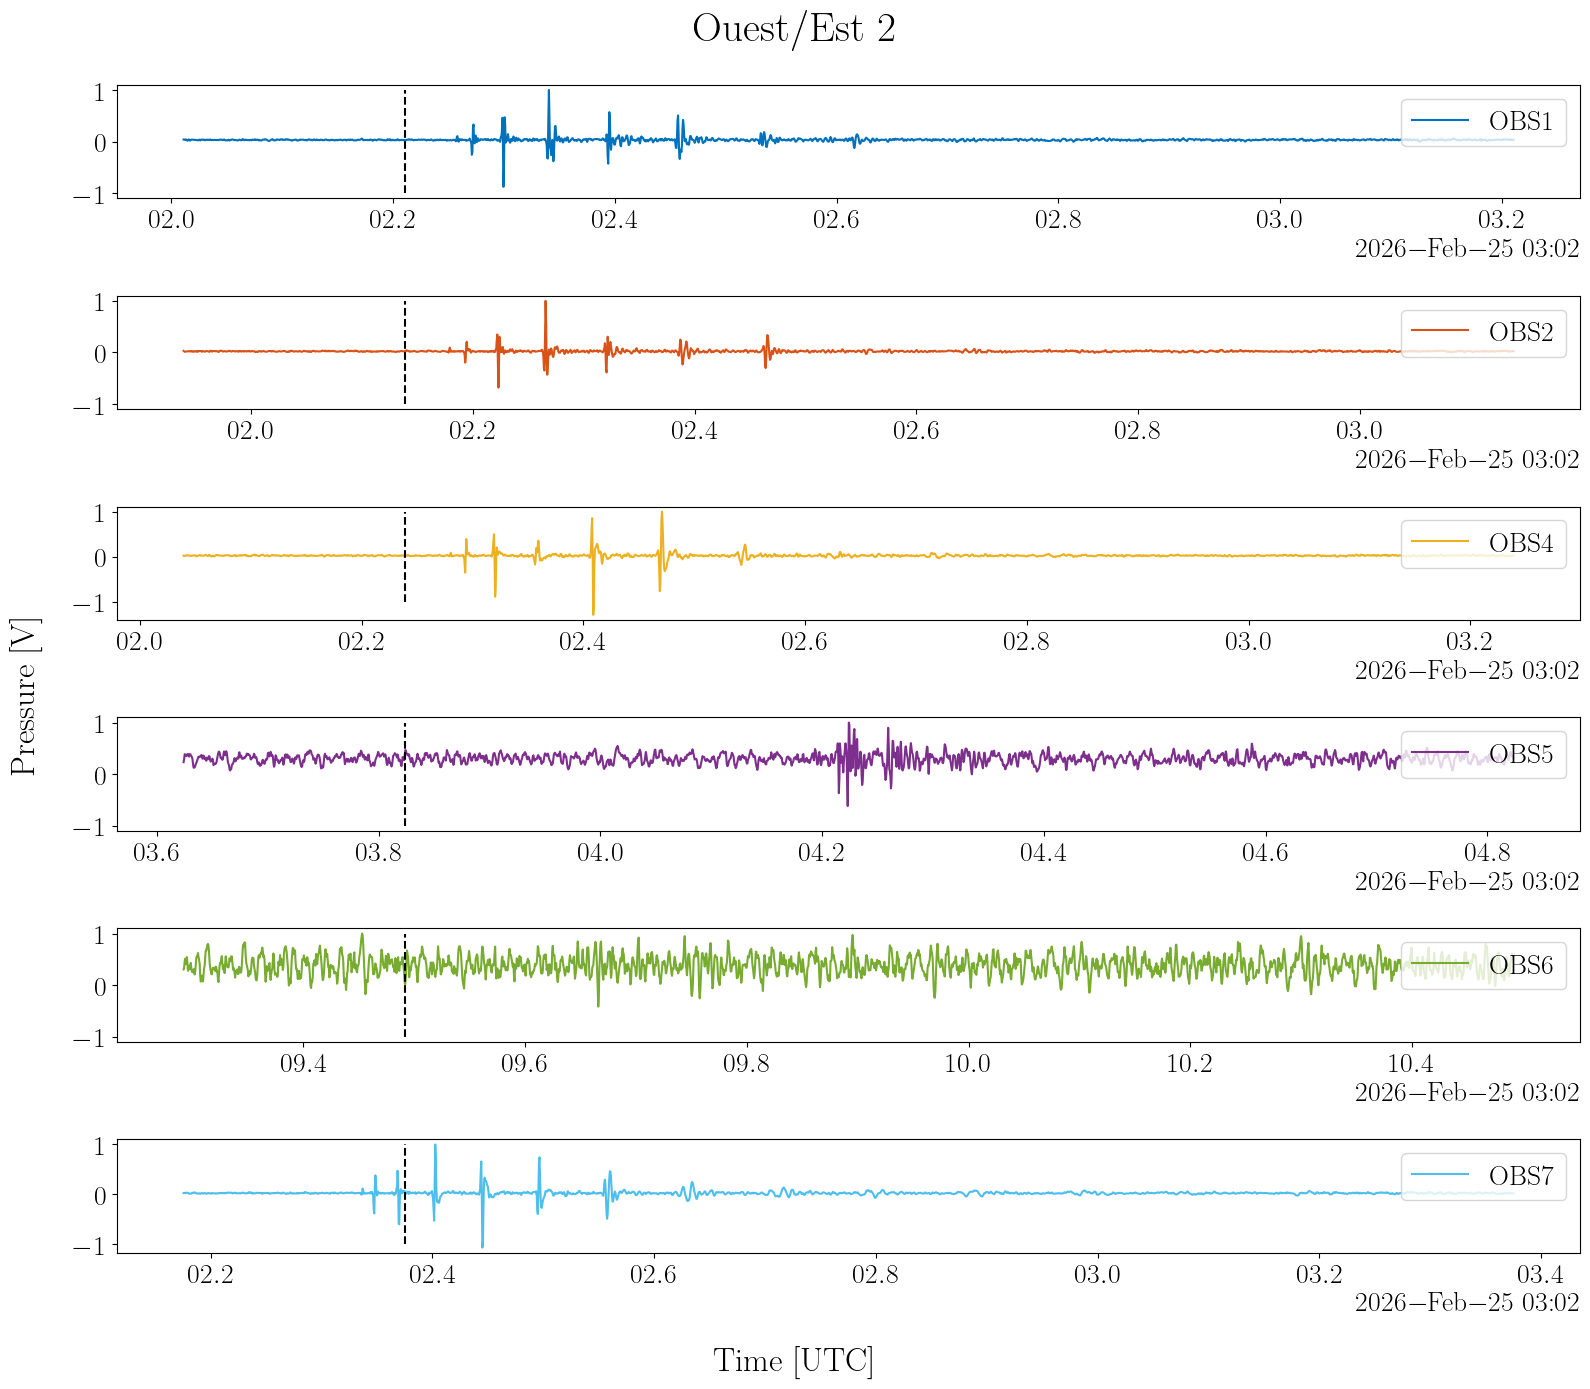

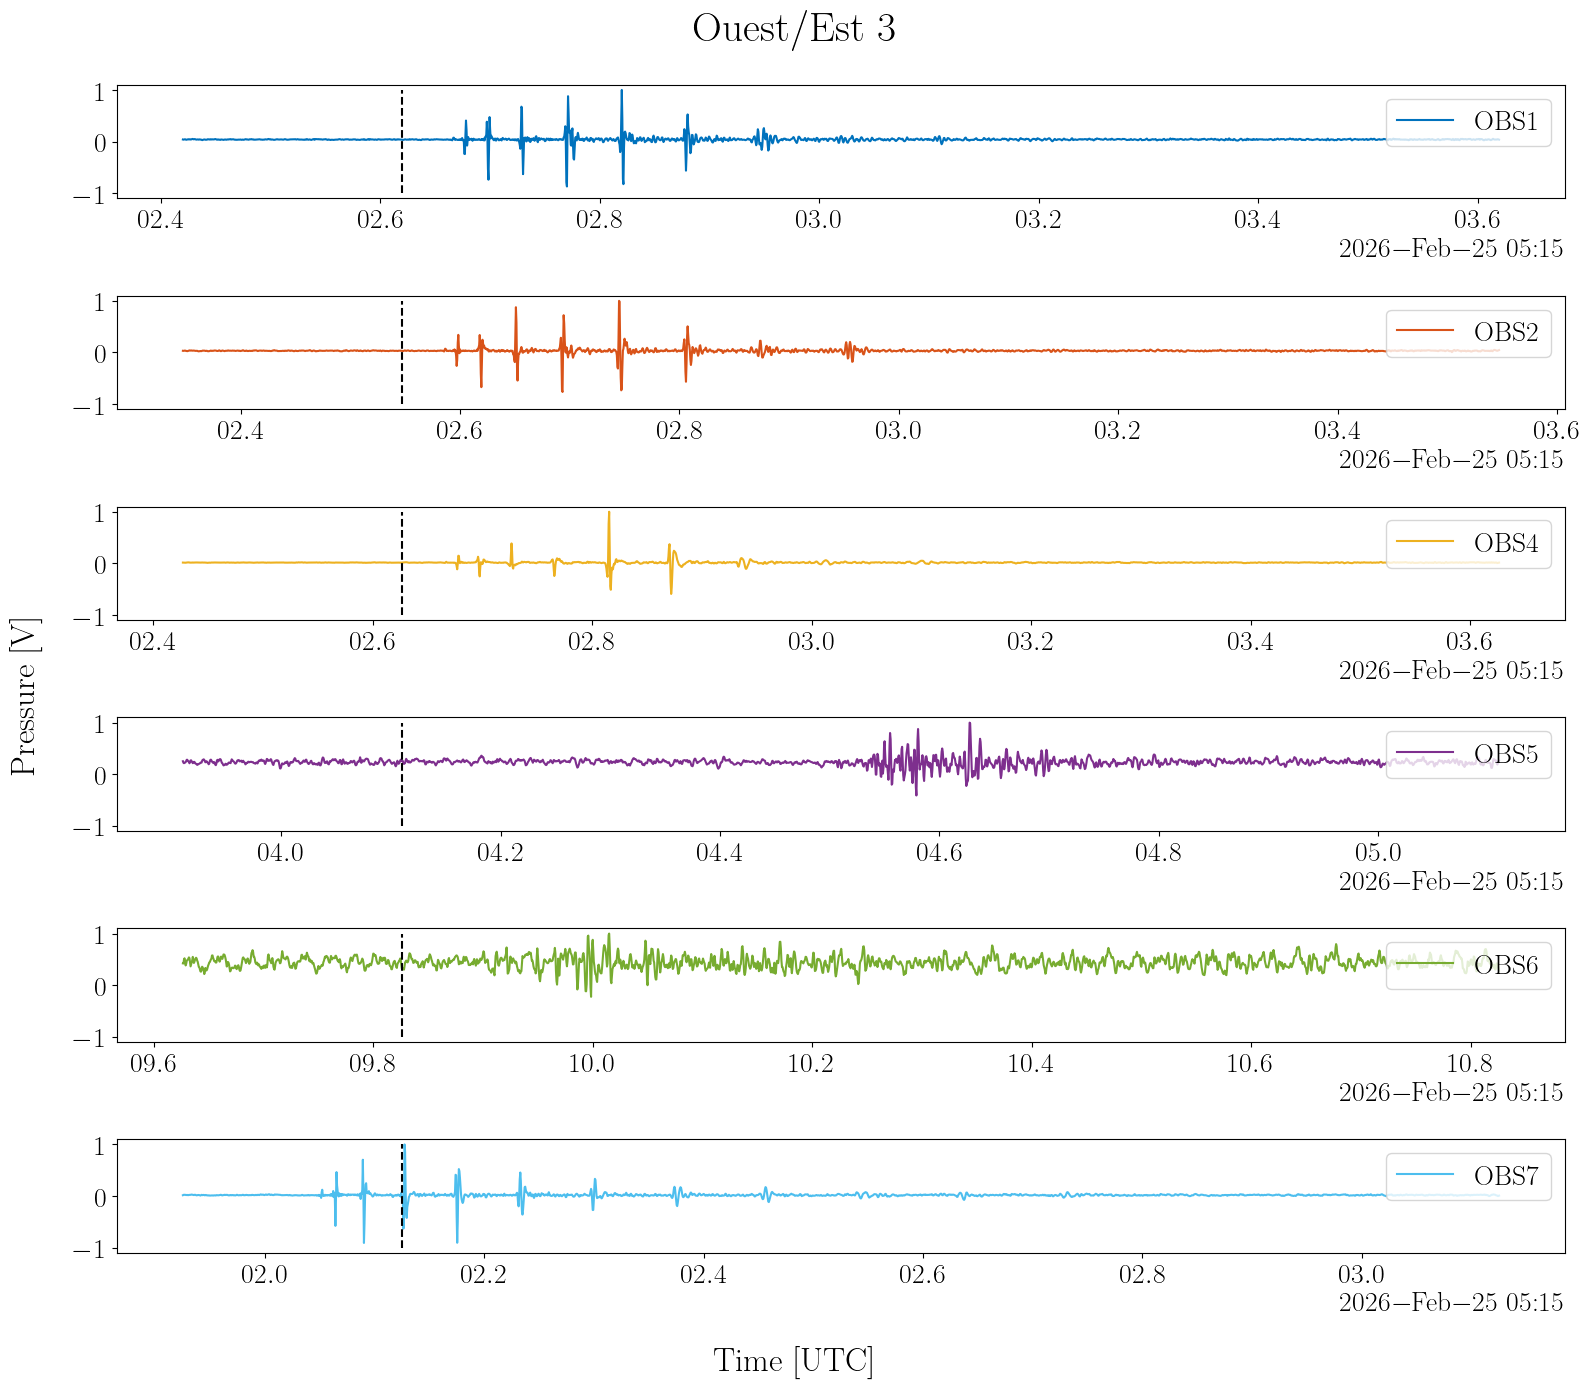

In [7]:
nb_tir = 1
offset1 = 200
offset2 = 1000
obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
# obs_ids = obs_ids[[0, 3, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

## Séléction d'une émission 


Text(0.02, 0.5, 'Pressure [V]')

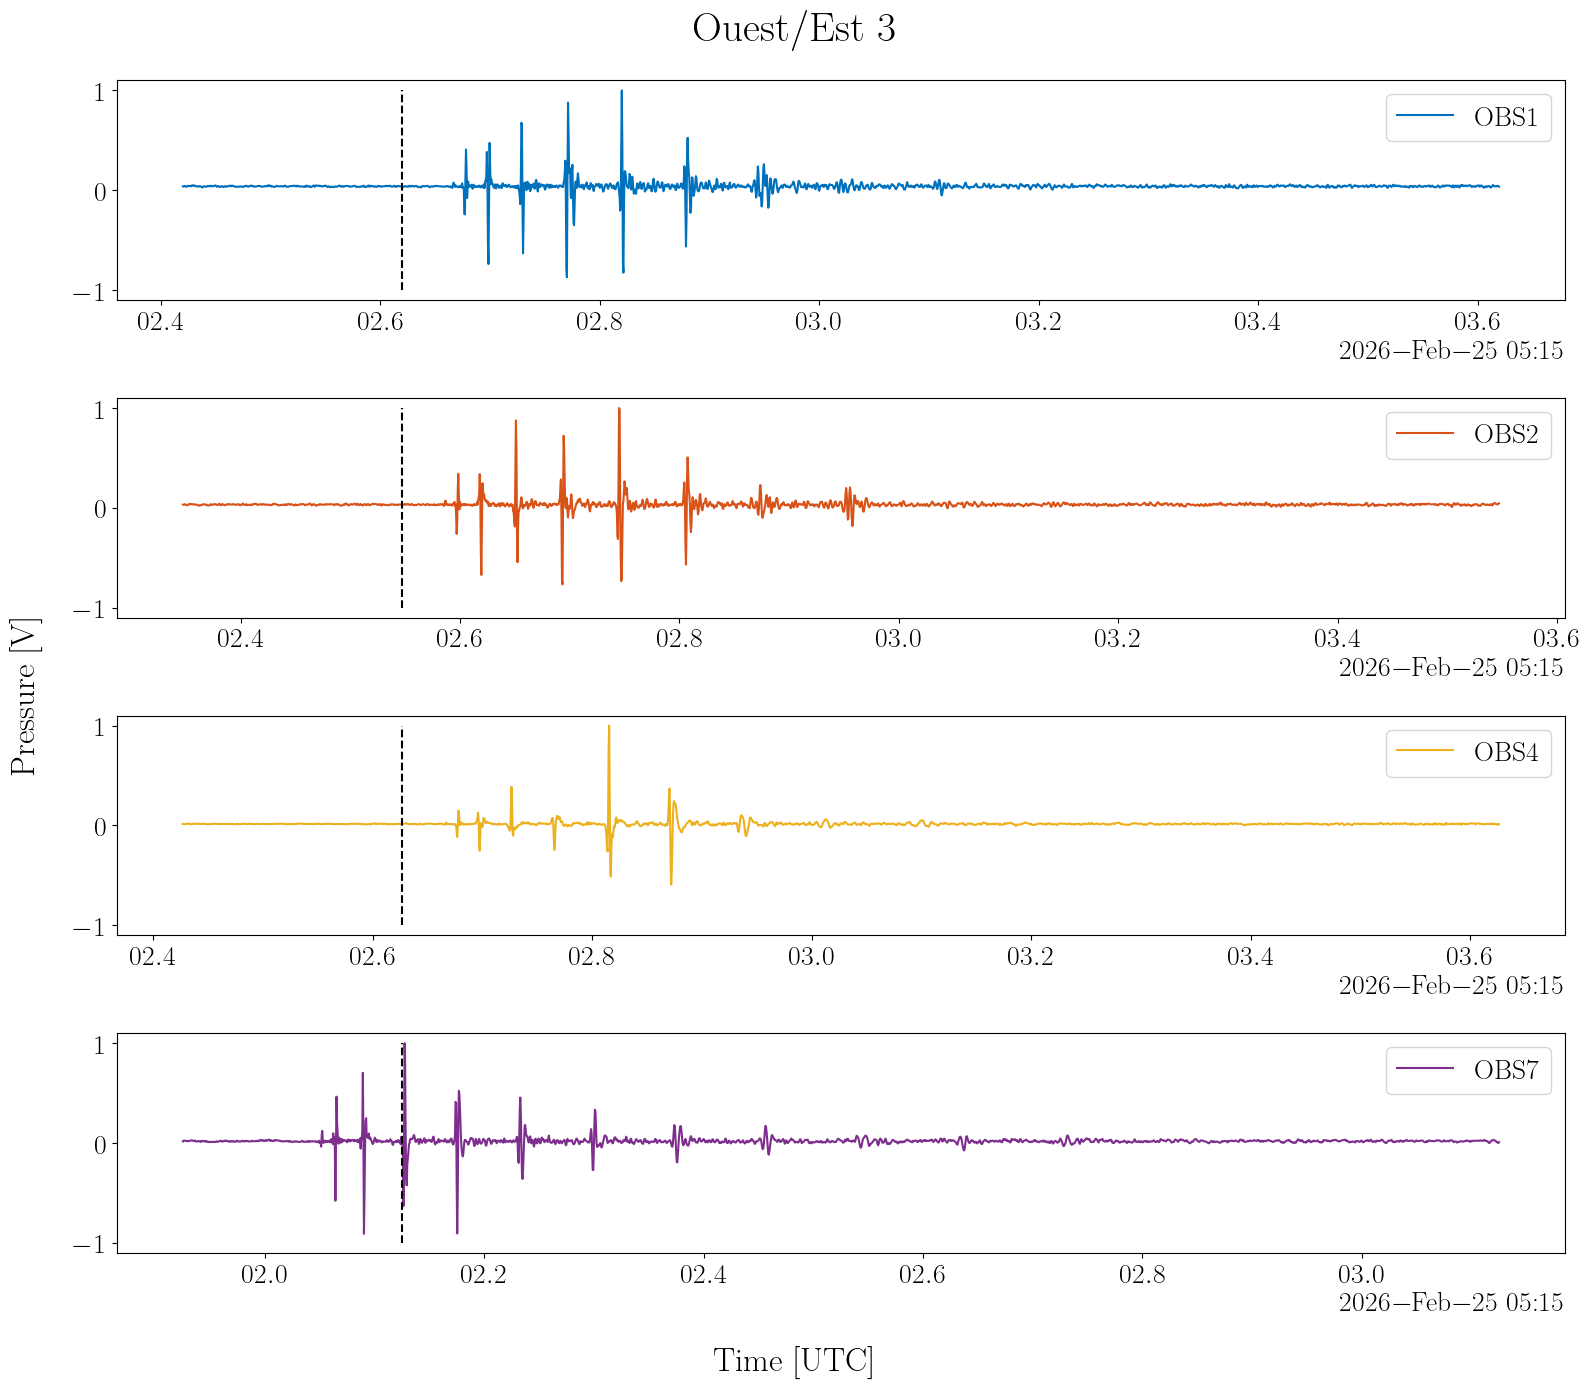

In [8]:
nb_tir = 1
offset1 = 200
offset2 = 1000

# Select OBS 1, 2, 4, and 7
obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
obs_ids = obs_ids[[0, 1, 2, 5]]
ds_pos_section = portion.position["oe3"].to_dataset().sel(rcv_id=obs_ids)
ds_pos_section = ds_pos_section.isel(src_datetime=slice(0, 0 + nb_tir))
ds_pressure_section = portion.pressure["oe3"].to_dataset()

tir_dt = ds_pos_section["tir_reception_datetime"]
fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)
axs = axs.flatten()
for i, rcv_id in enumerate(obs_ids):
    tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
    # Select associated data window
    press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel(
        {
            f"time_{rcv_id}": slice(
                tir_dt_rcv.values[0] - np.timedelta64(offset1, "ms"),
                tir_dt_rcv.values[-1] + np.timedelta64(offset2, "ms"),
            )
        }
    )
    # Plot pressure signal
    # Normalize
    press_rcv = press_rcv / press_rcv.max()
    press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
    # Plot arrivals time
    axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
    # Add legend
    axs[i].legend(loc="upper right")

xlab = axs[0].get_xlabel()
ylab = axs[0].get_ylabel()

for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

fig.suptitle(
    f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}"
)
fig.supxlabel(xlab)
fig.supylabel(ylab)

# Bathymétrie dans la zone 

In [9]:
ds_bathy = xr.open_dataset(ACOUPLANE_BATHY_NC_FPATH)

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


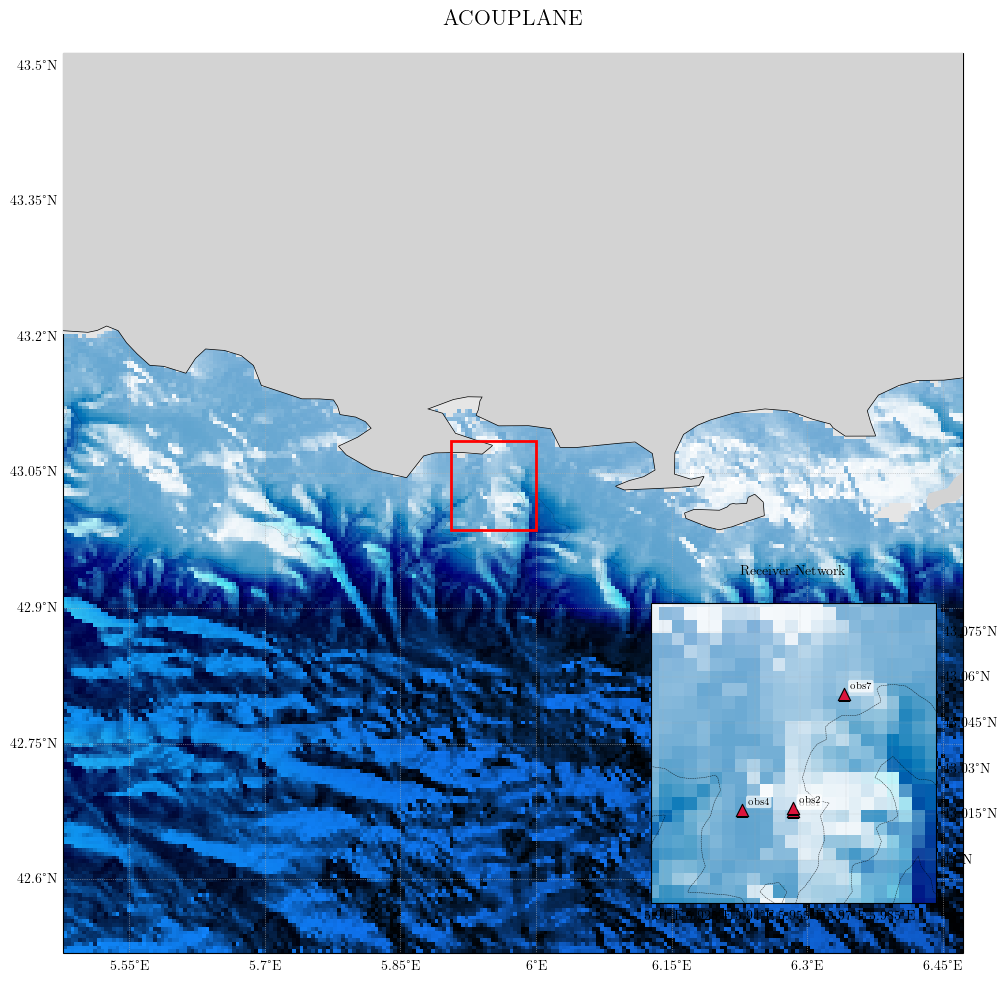

In [10]:
import numpy as np
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import LightSource
from matplotlib.patches import Rectangle

# # =============================================================================
# # INPUT DATA
# # =============================================================================

# Extract data
z = ds_bathy["elevation"].values
lon = ds_bathy["lon"].values
lat = ds_bathy["lat"].values

# # Receiver dataset
# rx_lon = np.array([obs4_lon, obs7_lon])
# rx_lat = np.array([obs7_lat, obs7_lat])
# rx_id = [4, 7]

# Receiver dataset
rx_lon = ds_pos_section.rcv_lon.values
rx_lat = ds_pos_section.rcv_lat.values
# rx_id = [int(obs_id[-1]) for obs_id in ds_pos_section.rcv_id.values]
rx_id = ds_pos_section.rcv_id.values

# =============================================================================
# DEFINE ZOOM AREA FROM RECEIVER NETWORK
# =============================================================================

pad = 0.03  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

# =============================================================================
# HILLSHADE
# =============================================================================

ls = LightSource(
    azdeg=315,
    altdeg=45,
)

# Hillshade computed on bathymetry
rgb = ls.shade(
    -z,  # invert bathymetry for proper relief
    cmap=plt.cm.Blues,
    vert_exag=8,
    blend_mode="overlay",
)


# =============================================================================
# FIGURE
# =============================================================================

fig = plt.figure(figsize=(14, 10))

# -----------------------------------------------------------------------------
# MAIN MAP
# -----------------------------------------------------------------------------

ax = fig.add_axes(
    [0.05, 0.05, 0.90, 0.90],
    projection=ccrs.PlateCarree(),
)

ax.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Bathymetric contours
levels = np.arange(
    np.floor(z.min() / 100) * 100,
    0,
    1000,
)

cs = ax.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.3,
    alpha=0.4,
    transform=ccrs.PlateCarree(),
)


# Zoom rectangle
rect = Rectangle(
    (zoom_extent[0], zoom_extent[2]),
    zoom_extent[1] - zoom_extent[0],
    zoom_extent[3] - zoom_extent[2],
    fill=False,
    edgecolor="red",
    linewidth=2,
    transform=ccrs.PlateCarree(),
    zorder=20,
)

ax.add_patch(rect)

# Grid
gl = ax.gridlines(
    draw_labels=True,
    linestyle=":",
    linewidth=0.5,
)

gl.top_labels = False
gl.right_labels = False

ax.set_title(
    # "Bathymetry and Receiver Network",
    "ACOUPLANE",
    fontsize=16,
)


# Create mask
land_mask = z >= 0

# Land color (RGB)
land_color = np.array([0.9, 0.9, 0.9])

# Replace land pixels by a uniform color
rgb_land = rgb.copy()
rgb_land[land_mask, :3] = land_color
rgb_land[~land_mask] = np.nan


ax.imshow(
    rgb_land,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
    zorder=16,
)

# Coastlines and land
ax.coastlines(resolution="10m", linewidth=1, zorder=17)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=17)

# =============================================================================
# INSET MAP
# =============================================================================

axins = fig.add_axes(
    [0.55, 0.10, 0.30, 0.30],  # left, bottom, width, height
    projection=ccrs.PlateCarree(),
)

# Bathymetry in inset
axins.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Bathymetric contours
levels = np.arange(
    np.floor(z.min() / 100) * 100,
    0,
    500,
)

# Contours
cs = axins.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.3,
    alpha=1,
    transform=ccrs.PlateCarree(),
)


# Receivers
axins.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=40,
)

# Receiver labels
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    axins.annotate(
        str(rid),
        (x, y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.7,
        ),
        zorder=41,
    )

# Zoom extent
axins.set_extent(zoom_extent)

# Grid
gl2 = axins.gridlines(
    draw_labels=True,
    linestyle=":",
    linewidth=0.3,
)

gl2.top_labels = False
gl2.right_labels = True
gl2.left_labels = False

axins.set_title(
    "Receiver Network",
    fontsize=10,
)


plt.show()

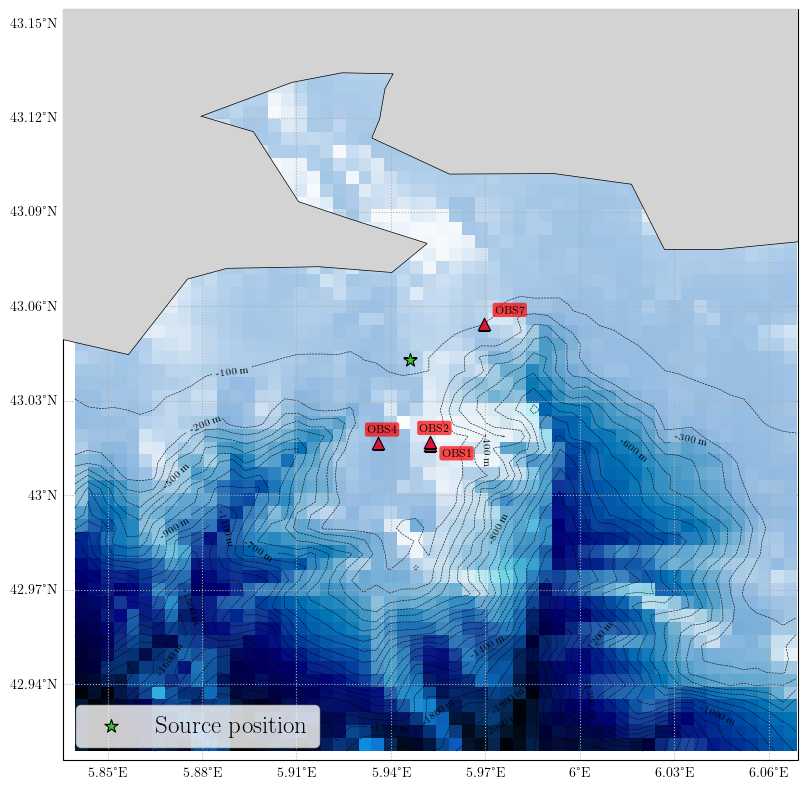

In [11]:
# Plot source position for selected ranges
pad = 0.1  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

bathy_zoom = ds_bathy.sel(
    lon=slice(zoom_extent[0], zoom_extent[1]), lat=slice(zoom_extent[2], zoom_extent[3])
)


z = bathy_zoom["elevation"].values
lon = bathy_zoom["lon"].values
lat = bathy_zoom["lat"].values

# Hillshade
ls = LightSource(azdeg=315, altdeg=45)  # illumination azimuth  # illumination elevation
rgb = ls.shade(-z, cmap=plt.cm.Blues, vert_exag=5, blend_mode="overlay")

# Figure
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())


# Shaded bathymetry
ax.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Optional depth contours
levels = np.arange(np.floor(z.min() / 100) * 100, 0, 100)

cs = ax.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.4,
    alpha=1,
    transform=ccrs.PlateCarree(),
)

ax.clabel(cs, fmt="%d m", fontsize=7)

# Coastlines and land
ax.coastlines(resolution="10m", linewidth=1, zorder=17)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=17)

# Grid
gl = ax.gridlines(draw_labels=True, linestyle=":")
gl.top_labels = False
gl.right_labels = False

ax.set_title("")

# Receivers
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Receiver labels
i = 0
sign_x = [1, -1, -1, 1, 1, 1, 1, -1]
sign_y = [-1, 1, 1, 1, 1, 1, -1, 1]
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    ax.annotate(
        str(rid).upper(),
        (x, y),
        xytext=(sign_x[i]*8, sign_y[i]*8),
        textcoords="offset points",
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="red",
            ec="none",
            alpha=0.7,
        ),
        zorder=11,
    )
    i += 1

# Add source position
ax.scatter(
    ds_pos_section.tir_src_lon,
    ds_pos_section.tir_src_lat,
    s=100,
    c="limegreen",
    marker="*",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
    label="Source position"
)


# Zoom on the area of interest
ax.set_extent(zoom_extent)

ax.legend(fontsize=18, loc="lower left")

fpath = os.path.join(ROOT_IMG_PROPAGATION, "bathy_portion1.png")
fig.savefig(fpath)

# Modélisation de la propagation 

## Extraction des profils de bathymétrie 

In [12]:
from get_data.bathymetry.bathy_profile_extraction import extract_bathy_profile

In [13]:
# We need to rename elevation into bathymetry to use the functionbelow
xr_bathy = ds_bathy.rename(elevation="bathymetry")
xr_bathy

<xarray.Dataset> Size: 119kB
Dimensions:     (lat: 240, lon: 240)
Coordinates:
  * lat         (lat) float64 2kB 42.52 42.52 42.53 42.53 ... 43.51 43.51 43.51
  * lon         (lon) float64 2kB 5.477 5.481 5.485 5.49 ... 6.465 6.469 6.473
Data variables:
    bathymetry  (lat, lon) int16 115kB -2304 -2305 -2307 -2309 ... 244 214 167
Attributes:
    description:     Bathymetry data from GEBCO 2026
    geodesic_frame:  WGS84

In [14]:
bathy_profiles = {}
for rcv_id in ds_pos_section.rcv_id.values:
    r_profile, z_profile = extract_bathy_profile(
        xr_bathy=xr_bathy,
        start_lon=ds_pos_section.tir_src_lon.values[0],
        start_lat=ds_pos_section.tir_src_lat.values[0],
        stop_lon=ds_pos_section.sel(rcv_id=rcv_id).rcv_lon.values,
        stop_lat=ds_pos_section.sel(rcv_id=rcv_id).rcv_lat.values,
        range_resolution=100
    )
    z_profile = z_profile * -1  # Convert bathymetry to depth
    bathy_profiles[rcv_id] = {
            "range_m": r_profile,
            "depth_m": z_profile
    }

In [15]:
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)


# Add source position
ax.scatter(
    ds_pos_section.tir_src_lon,
    ds_pos_section.tir_src_lat,
    s=100,
    c="limegreen",
    marker="*",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
    label="Source position",
)

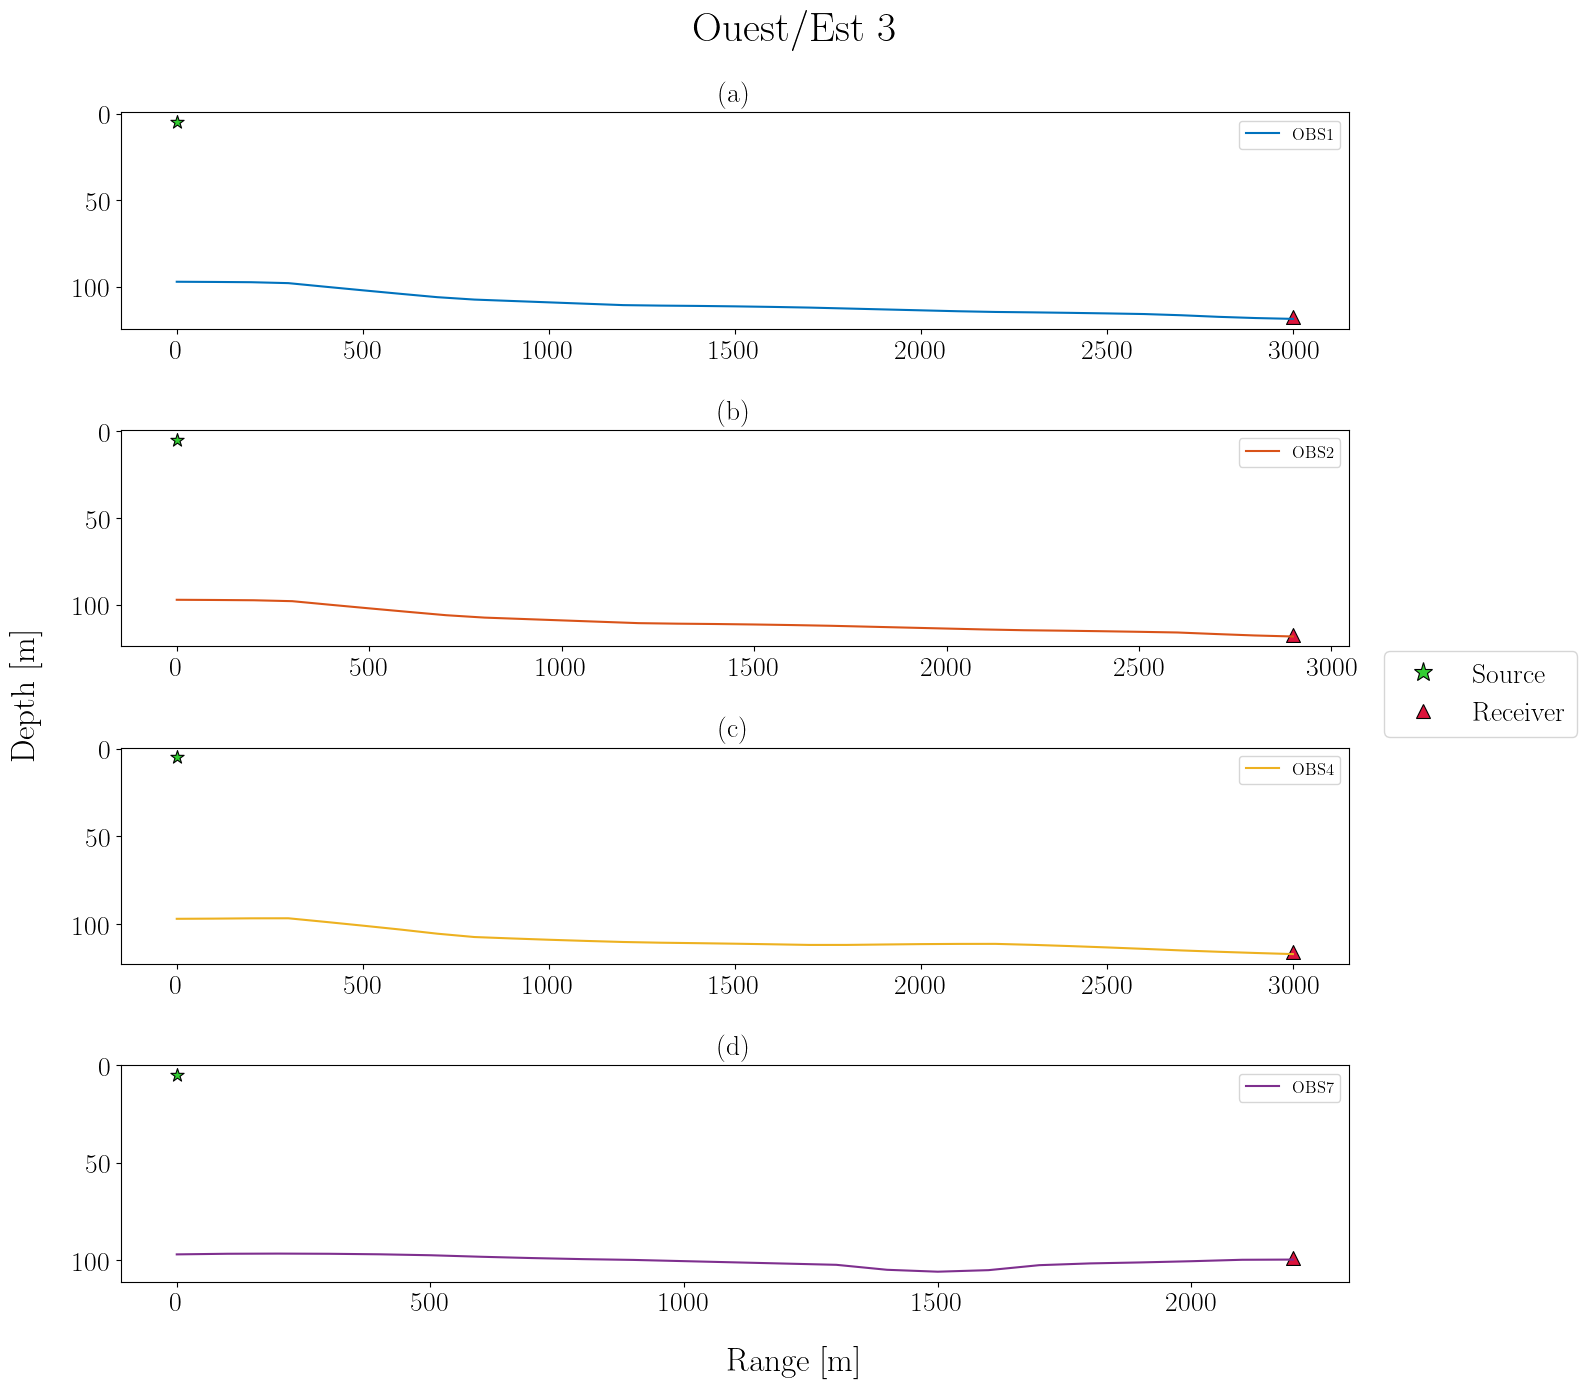

In [16]:
z_source = 5
fig, axs = plt.subplots(
    nrows=ds_pos_section.sizes["rcv_id"], ncols=1, figsize=(16, 14), sharex=False
)
axs = axs.flatten()
for i, rcv_id in enumerate(ds_pos_section.rcv_id.values):
    axs[i].plot(
        bathy_profiles[rcv_id]["range_m"],
        bathy_profiles[rcv_id]["depth_m"],
        label=rcv_id.upper(),
        color=color(i),
    )

    # Add source
    axs[i].scatter(
        bathy_profiles[rcv_id]["range_m"][0],
        z_source,
        s=100,
        c="limegreen",
        marker="*",
        edgecolors="black",
        linewidths=0.8,
        zorder=10,
        # label="Source",
    )
    # Add receiver
    axs[i].scatter(
        bathy_profiles[rcv_id]["range_m"][-1],
        bathy_profiles[rcv_id]["depth_m"][-1] - 1,
        s=100,
        c="crimson",
        marker="^",
        edgecolors="black",
        linewidths=0.8,
        # label="Receiver",
        # zorder=10,
    )

    # Add legend
    axs[i].legend(loc="upper right", fontsize=12)

for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")
    ax.invert_yaxis()

legend_handles = [
    Line2D(
        [0],
        [0],
        linestyle="None",
        marker="*",
        markersize=14,
        markerfacecolor="limegreen",
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="Source",
    ),
    Line2D(
        [0],
        [0],
        linestyle="None",
        marker="^",
        markersize=10,
        markerfacecolor="crimson",
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="Receiver",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="outside right center",
    ncols=1,
    fontsize=20,
)

fig.suptitle(
    f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}"
)
fig.supxlabel("Range [m]")
fig.supylabel("Depth [m]")

set_subfigures_abc_labels(axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom")

fpath = os.path.join(ROOT_IMG_PROPAGATION, "bathy_profiles_portion1.png")
fig.savefig(fpath)

## Profil de célérité 

In [17]:
celerity = xr.open_datatree(ACOUPLANE_CELERITY_NC_FPATH)
celerity

<xarray.DataTree>
Group: /
├── Group: /T0_00006
│       Dimensions:      (depth: 322)
│       Coordinates:
│         * depth        (depth) float64 3kB 0.0 0.6301 1.26 1.89 ... 198.8 199.4 200.0
│       Data variables:
│           temperature  (depth) float64 3kB ...
│           celerity     (depth) float64 3kB ...
│       Attributes:
│           longitude:                 5.9519785
│           latitude:                  43.0480848
│           surface_temperatude_degC:  14.2
│           pression_atmo_hPa:         1021.0
│           salinity_ppt:              37.5
├── Group: /T0_00007
│       Dimensions:      (depth: 253)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 156.2 156.8 157.4
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 5.9523738
│           latitude:                  43.0173035
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1020.2
│           salinity_ppt:              37.5
├── Group: /T0_00012
│       Dimensions:      (depth: 160)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 98.39 99.02 99.64
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 5.9512852
│           latitude:                  43.0566788
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1025.6
│           salinity_ppt:              37.5
├── Group: /T0_00020
│       Dimensions:      (depth: 233)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 143.8 144.4 145.0
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 6.2931097
│           latitude:                  42.9943315
│           surface_temperatude_degC:  14.1
│           pression_atmo_hPa:         1027.3
│           salinity_ppt:              37.5
├── Group: /T0_00021
│       Dimensions:      (depth: 111)
│       Coordinates:
│         * depth        (depth) float64 888B 0.0 0.6301 1.26 1.89 ... 67.8 68.42 69.05
│       Data variables:
│           temperature  (depth) float64 888B ...
│           celerity     (depth) float64 888B ...
│       Attributes:
│           longitude:                 6.269442
│           latitude:                  43.0373697
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1026.7
│           salinity_ppt:              37.5
├── Group: /T0_00022
│       Dimensions:      (depth: 144)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 88.41 89.04 89.66
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 6.2833635
│           latitude:                  43.058786
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1026.9
│           salinity_ppt:              37.4
...
├── Group: /T7_00011
│       Dimensions:      (depth: 836)
│       Coordinates:
│         * depth        (depth) float64 7kB 0.0 0.6472 1.294 ... 524.1 524.7 525.4
│       Data variables:
│           temperature  (depth) float64 7kB ...
│           celerity     (depth) float64 7kB ...
│       Attributes:
│           longitude:                 5.9700047
│           latitude:                  43.0205393
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1023.7
│           salinity_ppt:              37.5
├── Group: /T7_00013
│       Dimensions:      (depth: 561)
│       Coordinates:
│         * depth        (depth) float64 4kB 0.0 0.6472 1.294 ... 354.4 355.0 355.7
│       

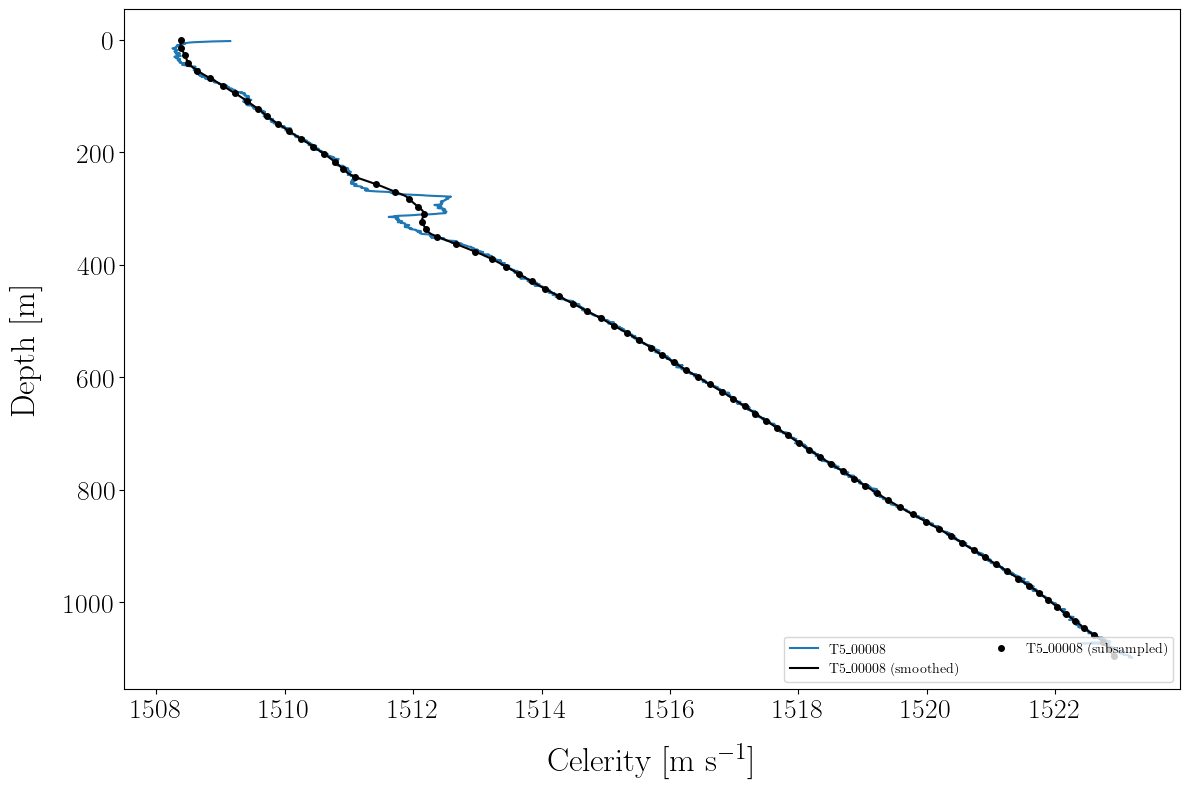

In [18]:
# selected_profile = "T7_00003"
# selected_profile = "T7_00019"
selected_profile = "T5_00008"

# selected_profile = "T0_00020"

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
for name, node in celerity.children.items():
    if name == selected_profile:
        ds_celerity = node.to_dataset()
        ds_celerity.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)

        # Apply rolling mean
        smooth_celerity_profile = ds_celerity.celerity.rolling(
            depth=100, center=True, min_periods=1
        ).mean()
        smooth_celerity_profile.plot(y="depth", ax=ax, yincrease=False, label=f"{name} (smoothed)", color="k")

        # Use smooth profile
        z_ssp, cp_ssp = smooth_celerity_profile.depth.values, smooth_celerity_profile.values
        # Subsample profile
        z_ssp = z_ssp[::20]
        cp_ssp = cp_ssp[::20]
        ax.plot(cp_ssp, z_ssp, "o", color="k", markersize=4, label=f"{name} (subsampled)")

ax.legend(loc="lower right", ncols=2, fontsize=10)
# plt.ylim(20, 0)
fpath = os.path.join(ROOT_IMG_PROPAGATION, "celerity_portion1.png")
fig.savefig(fpath)

## Calcul de la propa avec Kraken 

In [19]:
bathy_profiles

{np.str_('obs1'): {'range_m': array([   0,  100,  200,  300,  400,  500,  600,  700,  800,  900, 1000,
         1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100,
         2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900, 3000]),
  'depth_m': array([ 97.08931742,  97.1998154 ,  97.35404784,  97.88796101,
          99.97904709, 102.0263996 , 104.03002042, 105.98991137,
         107.38178661, 108.1812751 , 108.98076559, 109.78025807,
         110.57975255, 110.85846675, 111.04390916, 111.29493185,
         111.61153203, 112.00222847, 112.53042441, 113.05861765,
         113.58680819, 114.11499603, 114.52304272, 114.75887167,
         115.03840603, 115.36164394, 115.72858356, 116.42524442,
         117.34178696, 118.04286106, 118.52542171])},
 np.str_('obs2'): {'range_m': array([   0,  100,  200,  300,  400,  500,  600,  700,  800,  900, 1000,
         1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100,
         2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900]),


In [20]:
# Use smooth profile 
z_ssp, cp_ssp = smooth_celerity_profile.depth.values, smooth_celerity_profile.values
# Subsample profile 
z_ssp = z_ssp[::20]
cp_ssp = cp_ssp[::20]

In [21]:
from real_data_analysis.acouplane.src.analyse_portion.run_receivers_propagation import run_all_receivers

In [22]:
# run_all_receivers(
#     bathy_profiles, z_ssp, cp_ssp, run_kraken=False
# )  # d'abord : fichiers + figures d'environnement

In [23]:
# run_all_receivers(
#     bathy_profiles, z_ssp, cp_ssp, run_kraken=False
# )  # d'abord : fichiers + figures d'environnement
# results, failed = run_all_receivers(
#     bathy_profiles, z_ssp, cp_ssp, run_kraken=True, only=["obs1"], test_mode=True
# )  # puis un test
# run_all_receivers(bathy_profiles, z_ssp, cp_ssp, run_kraken=True)

In [24]:
# run_all_receivers(
#     bathy_profiles, z_ssp, cp_ssp, run_kraken=True, only=ds_pos_section.rcv_id.values
# )
run_all_receivers(bathy_profiles, z_ssp, cp_ssp, run_kraken=True, only=["obs1"])
run_all_receivers(bathy_profiles, z_ssp, cp_ssp, run_kraken=True, only=["obs2"])
run_all_receivers(bathy_profiles, z_ssp, cp_ssp, run_kraken=True, only=["obs4"])
run_all_receivers(bathy_profiles, z_ssp, cp_ssp, run_kraken=True, only=["obs7"])


===== Receiver obs1 =====
Note: extending KrakenField's receiver depth range from 119.0 m to 300.0 m (the bottom of the buffer sediment layer) -- FIELD.exe requires receivers to reach that depth to compute the coupled-mode coupling coefficients.


C:\Users\baptiste.menetrier\Desktop\devPy\phd\propa\kraken_toolbox\plot_utils.py:1318: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


Running Kraken  (parallel = True)...
Broadband range dependent kraken simulation completed.
obs1: diagnostic figures at [ 20. 280. 540. 800.] Hz


C:\Users\baptiste.menetrier\Desktop\devPy\phd\propa\kraken_toolbox\plot_utils.py:1125: UserWarning: The figure layout has changed to tight
  plt.tight_layout()



Done.

===== Receiver obs2 =====
Note: extending KrakenField's receiver depth range from 119.0 m to 300.0 m (the bottom of the buffer sediment layer) -- FIELD.exe requires receivers to reach that depth to compute the coupled-mode coupling coefficients.
Running Kraken  (parallel = True)...
Broadband range dependent kraken simulation completed.
obs2: diagnostic figures at [ 20. 280. 540. 800.] Hz

Done.

===== Receiver obs4 =====
Note: extending KrakenField's receiver depth range from 118.0 m to 300.0 m (the bottom of the buffer sediment layer) -- FIELD.exe requires receivers to reach that depth to compute the coupled-mode coupling coefficients.
Running Kraken  (parallel = True)...
Broadband range dependent kraken simulation completed.
obs4: diagnostic figures at [ 20. 280. 540. 800.] Hz

Done.

===== Receiver obs7 =====
Note: extending KrakenField's receiver depth range from 106.0 m to 300.0 m (the bottom of the buffer sediment layer) -- FIELD.exe requires receivers to reach that depth

({'obs7': (array([[[[[-2.1815561e-16+2.15085250e-16j,
              -4.6611952e-17+1.15275824e-16j,
               2.0963801e-18+8.73807857e-17j, ...,
              -1.2019229e-19+5.78812344e-19j,
               1.6168015e-19+5.67804845e-19j,
               4.0604725e-19+4.27590700e-19j],
             [-8.5741410e-04+8.42472538e-04j,
              -1.8045075e-04+4.52352047e-04j,
               1.2027216e-05+3.41230218e-04j, ...,
              -9.1441052e-07+2.50918674e-06j,
               3.7919872e-07+2.61229047e-06j,
               1.5570444e-06+2.09717041e-06j],
             [-1.7148282e-03+1.68494508e-03j,
              -3.6090150e-04+9.04704095e-04j,
               2.4054432e-05+6.82460435e-04j, ...,
              -1.8288210e-06+5.01837349e-06j,
               7.5839745e-07+5.22458095e-06j,
               3.1140887e-06+4.19434082e-06j],
             ...,
             [ 1.7337259e-02-1.68996528e-02j,
               4.0295441e-03-8.93473160e-03j,
               3.3934868e-04-6.88487

## Lecture des résultats et calcul de la réponse impulsionnelle

In [25]:
import pickle
from pathlib import Path

root_simulation = Path(
    r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis"
    r"\acouplane\src\analyse_portion\portion1\propagation"
)


def load_receiver(name, root=root_simulation, mmap=True):
    """Return (pressure_field, field_pos, freq) saved by run_receiver for one receiver."""
    d = Path(root) / str(name)
    # mmap_mode="r": the file is read from disk on demand (useful for the ~6 GB arrays)
    pressure_field = np.load(d / "pressure_field.npy", mmap_mode="r" if mmap else None)
    freq = np.load(d / "freq.npy")
    with open(d / "field_pos.pkl", "rb") as fh:
        field_pos = pickle.load(fh)
    return pressure_field, field_pos, freq


# One receiver
pressure_field, field_pos, freq = load_receiver("obs1")
print(pressure_field.shape, pressure_field.dtype)  # (n_freq, n_z, n_r)

# All the receivers (lazy: nothing is loaded in RAM until you slice the arrays)
receivers = ds_pos_section.rcv_id.values
results = {name: load_receiver(name) for name in receivers}

(781, 1, 1, 201, 501) complex64


In [26]:
results.keys()

dict_keys([np.str_('obs1'), np.str_('obs2'), np.str_('obs4'), np.str_('obs7')])

In [27]:
# ---- Frequency / time grids (computed once, outside the loop)
from real_data_analysis.acouplane.src.analyse_portion.run_receivers_propagation import NT, FS
freq = np.fft.rfftfreq(n=NT, d=1.0 / FS)
Sf = np.ones_like(freq)  # source spectrum on the FULL rfft grid (includes f = 0)

nfft = 2 * (freq.size - 1)  # = nt
df = freq[1] - freq[0]
nfft_inv = 4 * nfft  # Jensen et al. (2000) p.616: dt < 1 / (8 fmax)
dt = 1.0 / (nfft_inv * df)
time_vector = np.arange(nfft_inv) * dt  # exactly nfft_inv samples

k0 = 2 * np.pi * freq / c0
norm_factor = np.exp(1j * k0) / (4 * np.pi)

tau = ds_pos_section["tps_propagation_s"]
rcv_ids = ds_pos_section.rcv_id.values

impulse_responses = {}
# fig, axs = plt.subplots(nrows=len(rcv_ids), ncols=1, figsize=(16, 14), squeeze=False)
# axs = axs.flatten()

tau_rcvs = [0.742, 0.681, 0.75, 0.332]
for i, rcv_id in enumerate(rcv_ids):
    # tau_rcv = tau.sel(rcv_id=rcv_id).values[0]
    tau_rcv = tau_rcvs[i]

    # Transfer function at the receiver position (results[rcv_id] = (pressure, field_pos, freq_sim))
    pressure_rcv, pos_rcv, f_sim = results[rcv_id]
    pressure_rcv = pressure_rcv.squeeze()  # (n_freq_sim, n_z, n_r)
    r_grid, z_grid = pos_rcv["r"]["r"], pos_rcv["r"]["z"]

    idx_r = np.argmin(np.abs(r_grid - bathy_profiles[rcv_id]["range_m"][-1]))
    zrcv = bathy_profiles[rcv_id]["depth_m"][-1] - 1  # 1 m above the seafloor
    idx_z = np.argmin(np.abs(z_grid - zrcv))
    tf_sim = np.asarray(pressure_rcv[:, idx_z, idx_r], dtype=complex)

    # Put the computed frequencies on the full rfft grid (f = 0 and skipped bins -> 0)
    tf = np.zeros(freq.size, dtype=complex)
    tf[np.rint(f_sim / df).astype(int)] = tf_sim

    # Propagation delay, Y = S H
    delay_rcv = np.exp(1j * 2 * np.pi * tau_rcv * freq)
    y_f = Sf * tf * norm_factor * delay_rcv

    # Inverse to get time response 
    y_t = np.fft.irfft(y_f, n=nfft_inv)

    impulse_responses[rcv_id] = y_t
    # axs[i].plot(time_vector, y_t)
    # axs[i].set_title(str(rcv_id))
    # axs[i].set_ylabel("Amplitude")

# axs[-1].set_xlabel("Time (s)")
# fig.tight_layout()

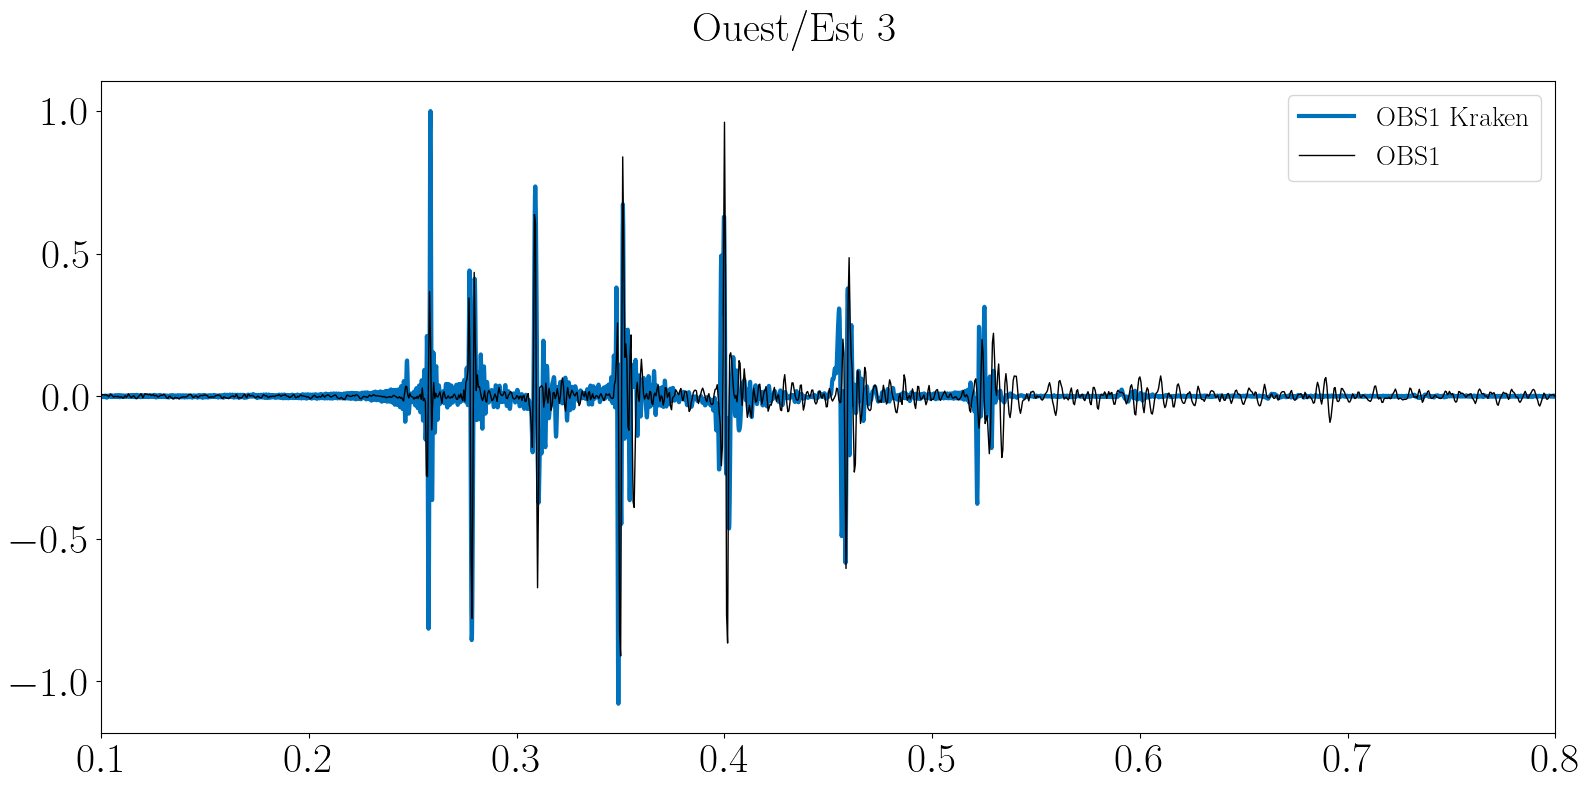

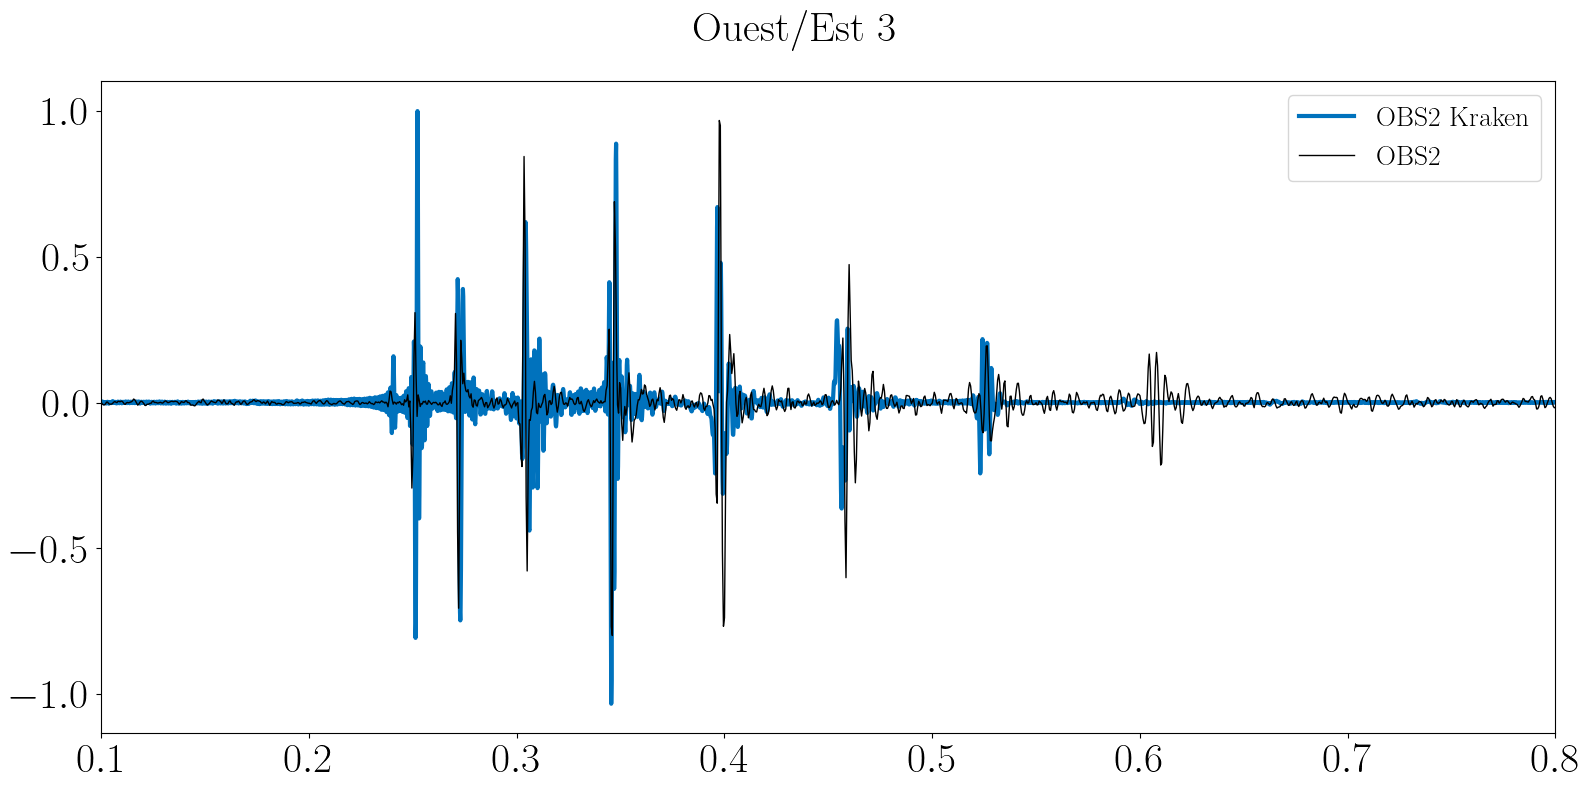

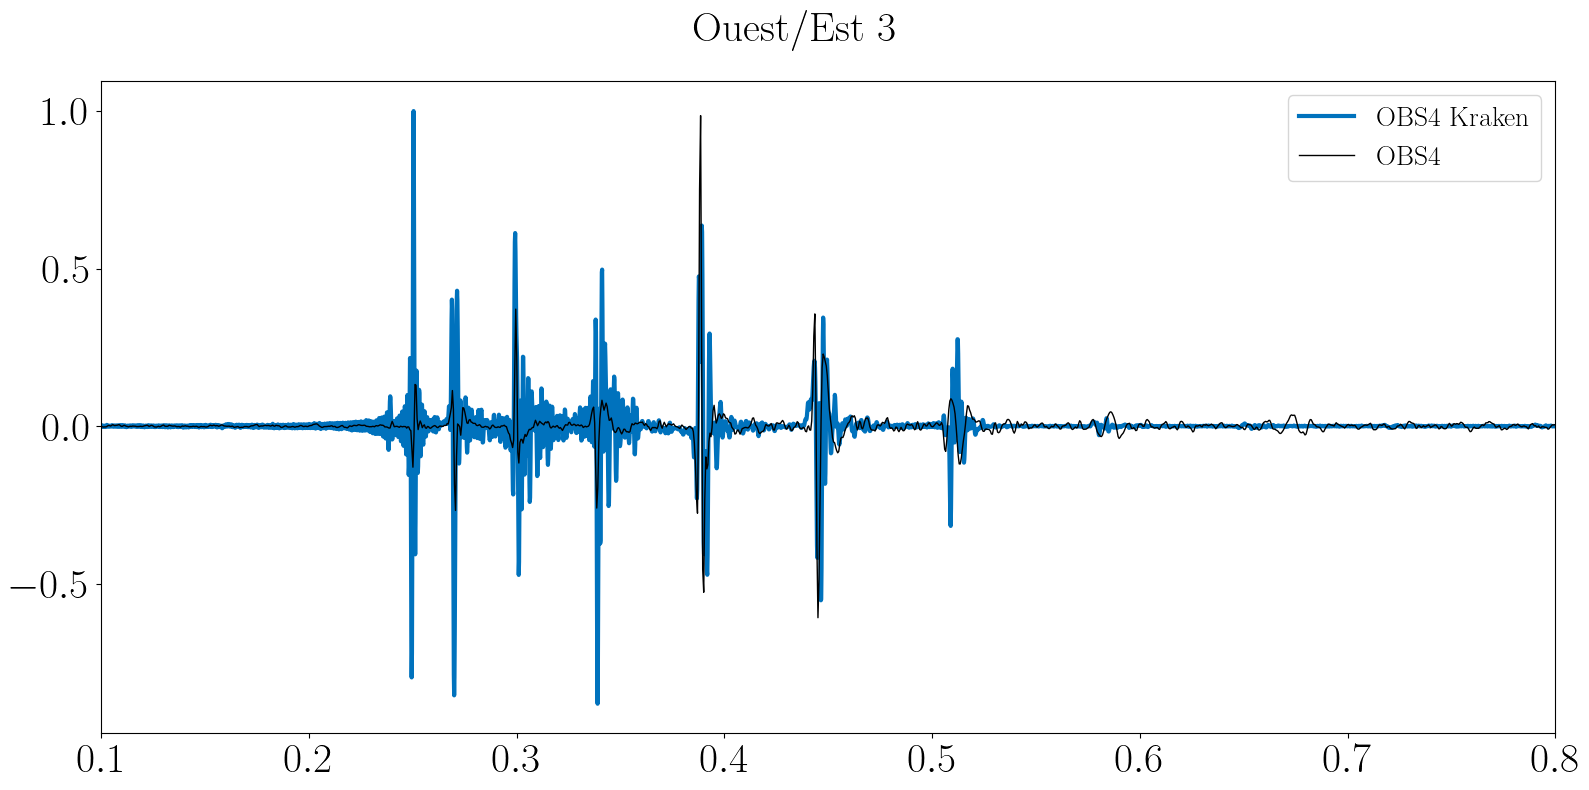

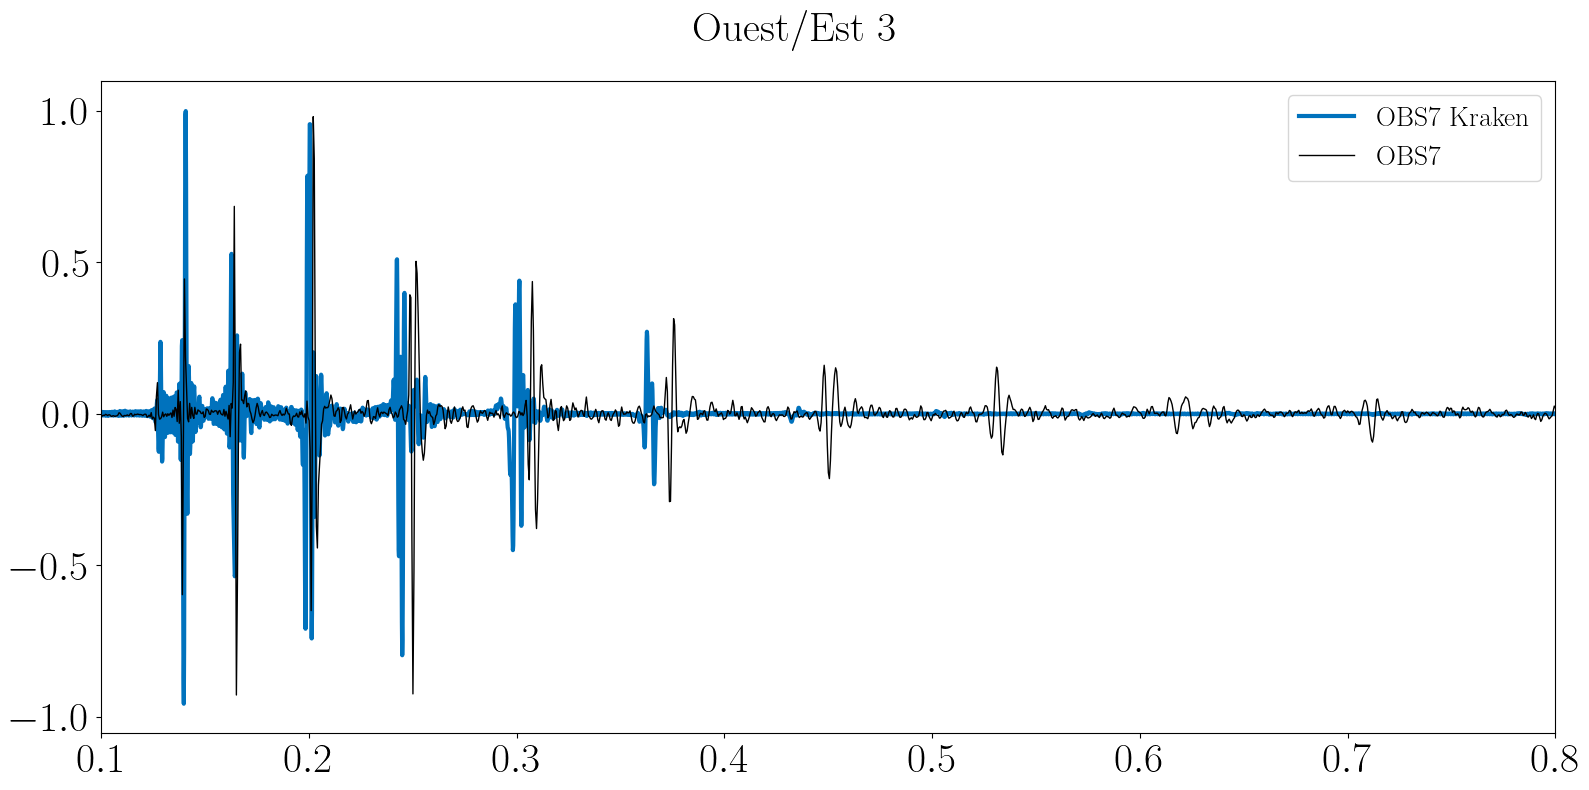

In [28]:
tir_dt = ds_pos_section["tir_reception_datetime"]
for i, rcv_id in enumerate(obs_ids):
    fig, ax= plt.subplots(nrows=1, ncols=1, figsize=(16, 8), sharex=False)

    tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
    # Select associated data window
    press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel(
        {
            f"time_{rcv_id}": slice(
                tir_dt_rcv.values[0] - np.timedelta64(offset1, "ms"),
                tir_dt_rcv.values[-1] + np.timedelta64(offset2, "ms"),
            )
        }
    )
    # Plot kraken ir
    y_t = impulse_responses[rcv_id]
    y_t = y_t / y_t.max()
    ax.plot(
        time_vector,
        y_t,
        color=color(0),
        linestyle="-",
        label=f"{rcv_id.upper()} Kraken",
        linewidth=3,
    )
    # Plot pressure signal
    # Normalize
    press_rcv = press_rcv / press_rcv.max()
    press_rcv = press_rcv - np.mean(press_rcv)
    # Time vector
    t_ns = press_rcv[f"time_{rcv_id}"] - press_rcv[f"time_{rcv_id}"].values[0]
    t_s = t_ns.values / np.timedelta64(1, 's')
    # Plot
    ax.plot(t_s, press_rcv.values, label=rcv_id.upper(), color="k", linewidth=1)

    # Add legend
    ax.legend(loc="upper right")

    # xlab = axs[0].get_xlabel()
    # ylab = axs[0].get_ylabel()

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

    fig.suptitle(
        f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}"
    )
    # fig.supxlabel(xlab)
    # fig.supylabel(ylab)
    plt.xlim(0.1, 0.8)

    fpath = os.path.join(
        ROOT_IMG_PROPAGATION, f"signal_vs_kraken_ir_{rcv_id.upper()}.png"
    )
    fig.savefig(fpath)

# Inversion de la position des OBS à partir des positions des tirs sismiques 

L'hypothèse la plus plausible à ce stade pour expliquer le décalage observée entre le temps d'arrivée théorique et le temps d'arrivée observé pour l'OBS 7. 

Pour tester cette hypothèse on peut inverser la position des OBS et en particulier de l'OBS 7 par moindres carrés. 

## Projection des coordonnées WGS84 dans un repère locale 
Afin d'appliquer la méthode des moindres carrés il est nécessaire de projeter les coordonnées dans un repère local ENU. 

Le centre du repère local est choisi comme la moyenne des positions des tirs de la portion 1 étudiée. 

In [8]:
from source.utils.utils_geo import geodetic_to_ecef, ecef_to_enu

### Définition de l'origine du repère 

Le centre du repère local est choisi comme la moyenne des positions des tirs de la portion 1 étudiée. 

In [9]:
local_frame_origin = {
    "lon": ds_pos_section.tir_src_lon.mean().values,
    "lat": ds_pos_section.tir_src_lat.mean().values, 
    "h": 0  # MSL
}
local_frame_origin

NameError: name 'ds_pos_section' is not defined

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\cartopy\mpl\geoaxes.py:1677: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  result = super().scatter(*args, **kwargs)


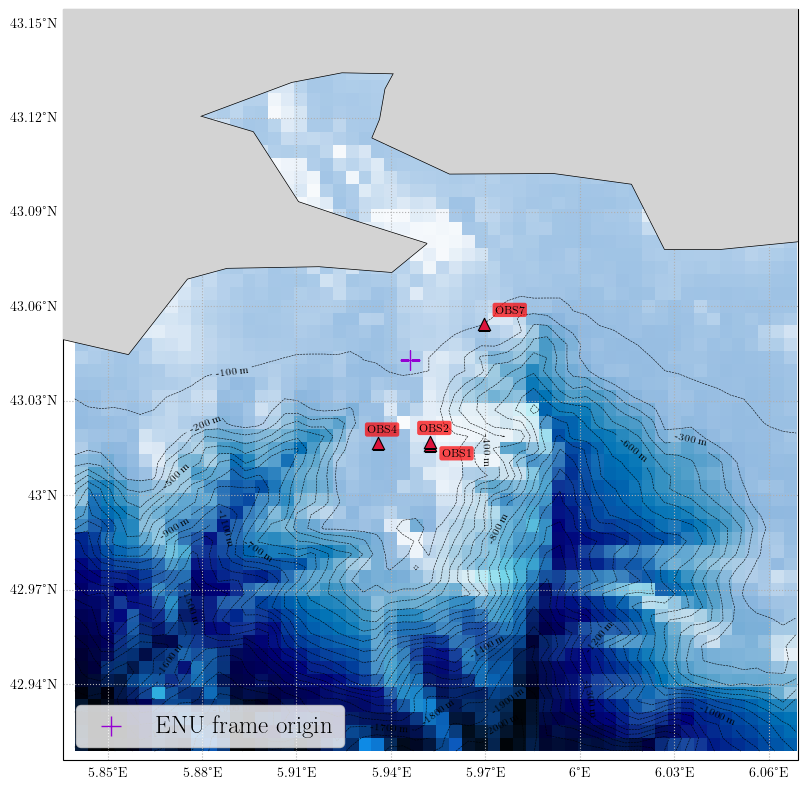

In [35]:
# Plot source position for selected ranges
pad = 0.1  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

bathy_zoom = ds_bathy.sel(
    lon=slice(zoom_extent[0], zoom_extent[1]), lat=slice(zoom_extent[2], zoom_extent[3])
)


z = bathy_zoom["elevation"].values
lon = bathy_zoom["lon"].values
lat = bathy_zoom["lat"].values

# Hillshade
ls = LightSource(azdeg=315, altdeg=45)  # illumination azimuth  # illumination elevation
rgb = ls.shade(-z, cmap=plt.cm.Blues, vert_exag=5, blend_mode="overlay")

# Figure
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())


# Shaded bathymetry
ax.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Optional depth contours
levels = np.arange(np.floor(z.min() / 100) * 100, 0, 100)

cs = ax.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.4,
    alpha=1,
    transform=ccrs.PlateCarree(),
)

ax.clabel(cs, fmt="%d m", fontsize=7)

# Coastlines and land
ax.coastlines(resolution="10m", linewidth=1, zorder=17)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=17)

# Grid
gl = ax.gridlines(draw_labels=True, linestyle=":")
gl.top_labels = False
gl.right_labels = False

ax.set_title("")

# Receivers
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Receiver labels
i = 0
sign_x = [1, -1, -1, 1, 1, 1, 1, -1]
sign_y = [-1, 1, 1, 1, 1, 1, -1, 1]
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    ax.annotate(
        str(rid).upper(),
        (x, y),
        xytext=(sign_x[i] * 8, sign_y[i] * 8),
        textcoords="offset points",
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="red",
            ec="none",
            alpha=0.7,
        ),
        zorder=11,
    )
    i += 1

# Add local frame origine position
ax.scatter(
    local_frame_origin["lon"],
    local_frame_origin["lat"],
    s=200,
    c="darkviolet",
    marker="+",
    edgecolors="black",
    linewidths=1,
    transform=ccrs.PlateCarree(),
    zorder=10,
    label="ENU frame origin",
)


# Zoom on the area of interest
ax.set_extent(zoom_extent)

ax.legend(fontsize=18, loc="lower left")

fpath = os.path.join(ROOT_IMG_PROPAGATION, "bathy_portion1.png")
fig.savefig(fpath)

In [31]:
ds_pos_section

<xarray.Dataset> Size: 528kB
Dimensions:                 (rcv_id: 4, atl_datetime: 596, mmsi: 526,
                             ais_datetime: 61, src_datetime: 1)
Coordinates:
  * rcv_id                  (rcv_id) <U4 64B 'obs1' 'obs2' 'obs4' 'obs7'
  * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T05:1...
  * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T05:...
  * src_datetime            (src_datetime) datetime64[ns] 8B 2026-02-25T05:15...
Dimensions without coordinates: mmsi
Data variables: (12/16)
    rcv_lon                 (rcv_id) float64 32B 5.953 5.953 5.936 5.97
    rcv_lat                 (rcv_id) float64 32B 43.02 43.02 43.02 43.05
    rcv_immersion           (rcv_id) int16 8B 119 116 118 93
    atl_lon                 (atl_datetime) float64 5kB ...
    atl_lat                 (atl_datetime) float64 5kB ...
    ais_lon                 (mmsi, ais_datetime) float64 257kB ...
    ...                      ...
    tir_src_lat             (src_datetime) float64 8B 43.04
    tir_vessel_lon          (src_datetime) float64 8B ...
    tir_vessel_lat          (src_datetime) float64 8B ...
    src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 32B 3.043e+03 ... ...
    tps_propagation_s       (rcv_id, src_datetime) float64 32B 2.02 ... 1.525
    tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 32B 2026-02...
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84
    portion_id:               1
    section_orientation:      Ouest/Est
    section_id:               3

### Ondulation du géoide 

Afin de définir convenablement l'origine du repère local ENU utilisé ainsi que la hauteur ellipsoïdale associée à chacune des positions GPS (et donc la composante z de la position de la source dans le repère ENU), il est nécessaire de connaitre l'élévation du géoïde (qui coïncide avec le niveau moyen de la mer) au-dessus de l'ellipsoïde de référence. 

Quelques définitions / notations : 

* H : altitude orthométrique (altitude au-dessus du géoïde)
* h : altitude géographique (hauteur au-dessus de l'ellipsoïde de référence WGS84), c'est l'altitude donnée par le positionnement GPS standard. 
* N : ondulation du géoïde (hauteur du géoïde au-dessus de l'ellipsoïde de référence)

Ces trois grandeurs sont reliées par la relation suivante : 

$$
h \approx H + N 
$$

L'approximation est valide au niveau millimétrique. 

Afin d'accéder à l'ondulation du géoïde N dans la zone d'intérêt il est nécessaire d'utiliser un modèle global du champ de pesanteur terrestre. Le modèle couramment utilisé est le modèle EGM2008. L'EGM2008 (Earth Gravitational Model EGM2008) est un modèle global du champ de pesanteur
terrestre diffusé sous la forme d’harmoniques sphériques développés jusqu’à l’ordre 2159 (Pavlis et al., 2012). Il est issu de données de gravimétrie terrestres, aéroportées et spatiales.

En python, il semble que l'on puisse accéder à une estimation de l'ondulation du géoïde à l'aide de la librairie geoid_toolkit. Cependant, la fonction geoid_undulation(lat, lon, "WGS84", clm, slm, lmax, R, GM) nécessite de fournir les paramètres du développement en harmoniques sphériques. Par soucis de simplicité, et au vu des incertitudes sur le reste des coordonnées verticales que l'on manipule ici, on se contente ici d'une valeur fournie par le site web https://geographiclib.sourceforge.io/cgi-bin/GeoidEval?input=47.5+-3.5&option=Submit pour la position de référence (origine du repère local). 

$$
lon_0 = 5.946085^\circ, lat_0 = 43.042972^\circ
$$
 
$$
N(lon_0, lat_0) = 48.5778 ~\text{m (EGM2008)} 
$$

In [38]:
N_geoid_undulation = 48.5

In [45]:
def transform_pos_wgs84_enu(
    lon, lat, local_frame_origin, N_geoid_undulation, zeta=0, sensor_h_above_sea_level=5
):
    lon = np.deg2rad(lon)
    lat = np.deg2rad(lat)
    # GPS h above WGS84 ellipsoid
    h = N_geoid_undulation + zeta + sensor_h_above_sea_level
    # WGS84 -> ECEF
    x, y, z = geodetic_to_ecef(lat, lon, h)
    # ECEF -> ENU
    lat0, lon0, h0 = (
        np.deg2rad(local_frame_origin["lat"]),
        np.deg2rad(local_frame_origin["lon"]),
        local_frame_origin["h"],
    )
    e, n, u = ecef_to_enu(x, y, z, lat0, lon0, h0)

    return e, n, u

### Projection des positions des tirs sismiques 

In [46]:
# Convert source position from WGS84 to ecef
tir_src_e, tir_src_n, tir_src_u = transform_pos_wgs84_enu(
    lon=ds_pos_section.tir_src_lon,
    lat=ds_pos_section.tir_src_lat,
    local_frame_origin=local_frame_origin,
    N_geoid_undulation=N_geoid_undulation,
    zeta=0,
    sensor_h_above_sea_level=-5,  # Source is approximately 5 meter below sea surface = MSL
)

### Projection des positions des OBS

In [47]:
# Convert OBS position from WGS84 to ecef
rcv_e, rcv_n, rcv_u = transform_pos_wgs84_enu(
    lon=ds_pos_section.rcv_lon,
    lat=ds_pos_section.rcv_lat,
    local_frame_origin=local_frame_origin,
    N_geoid_undulation=N_geoid_undulation,
    zeta=0,
    sensor_h_above_sea_level=-ds_pos_section.rcv_immersion,
)

array([ 531.0956799 ,  531.08731161, -822.11163462, 1907.5800763 ])

### Comparaison des positions dans les deux repères

On s'assure que tout est ok. 

In [6]:
def plot_portion_tir_pos(portion_tree, ax=None):
    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = plt.gcf()
        
    # i = 0
    for name, node in portion_tree.position.children.items():
        ds_pos_section = node.to_dataset()
        sc = ax.scatter(
            ds_pos_section.tir_src_lon,
            ds_pos_section.tir_src_lat,
            color=color(ds_pos_section.section_id),
            label=f"{ds_pos_section.section_orientation} {ds_pos_section.section_id}",
        )

    plot_obs_pos(ds_pos_section, ax=ax)

    return fig, ax

In [ ]:
def plot_portion_tir_pos_enu(portion_tree, ax=None):
    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = plt.gcf()

    # i = 0
    for name, node in portion_tree.position.children.items():
        ds_pos_section = node.to_dataset()
        sc = ax.scatter(
            ds_pos_section.tir_src_lon,
            ds_pos_section.tir_src_lat,
            color=color(ds_pos_section.section_id),
            label=f"{ds_pos_section.section_orientation} {ds_pos_section.section_id}",
        )

    plot_obs_pos(ds_pos_section, ax=ax)

    return fig, ax

(<Figure size 1600x800 with 2 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

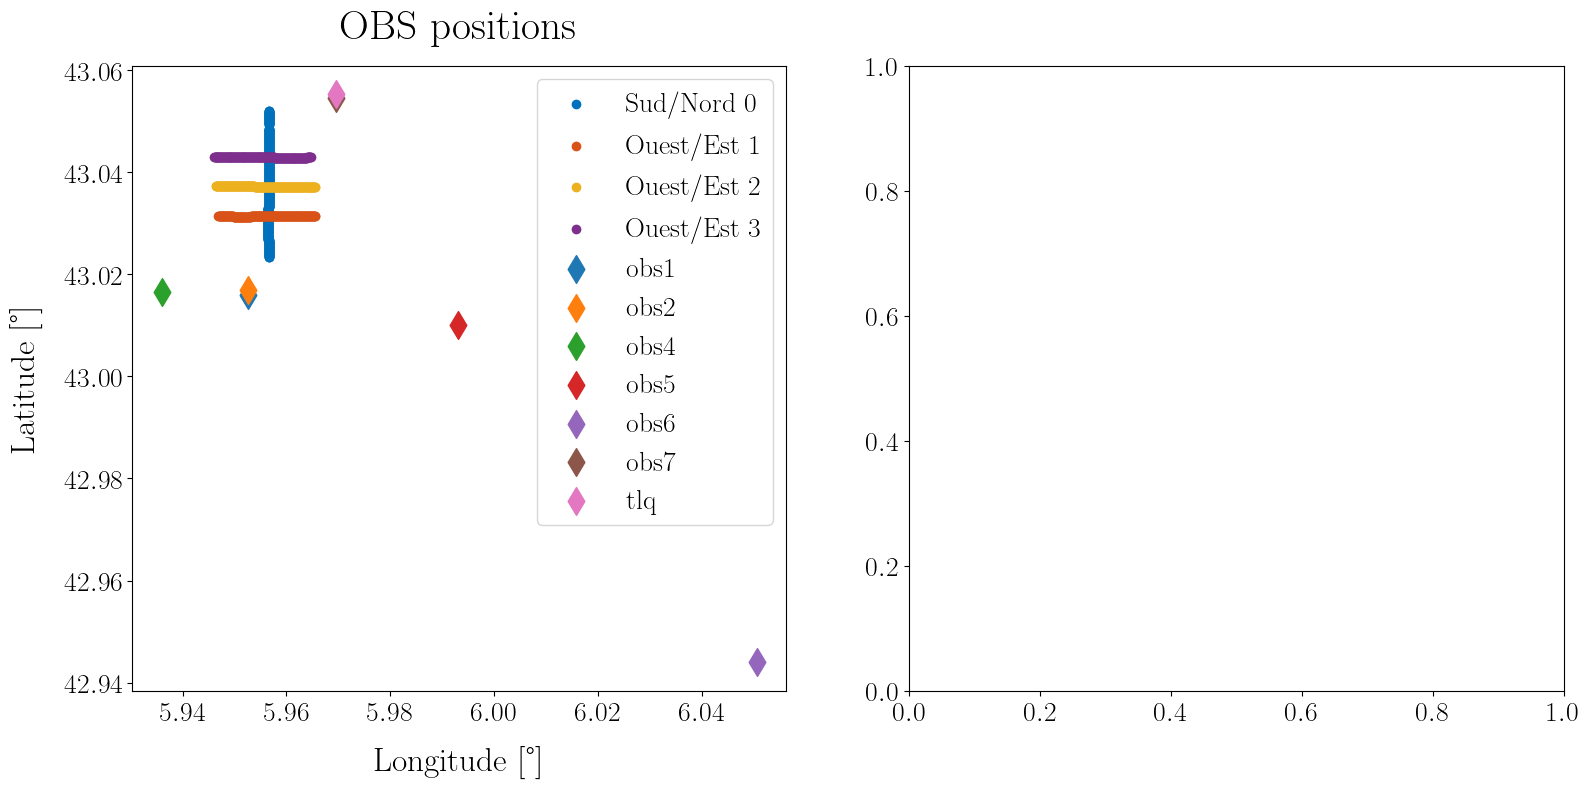

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))
plot_portion_tir_pos(portion, ax=axs[0])

In [29]:
from publication.publication_figure import PubFigure, color
from misc import equivalent_celerity, calc_wls, draw_ellipse

# ======================================================================================================================
# LMS
# ======================================================================================================================
def f(X, X_s):
    """
    Parameters
    ----------
    X : array
        [y, x, z] position of the hydrophone to estimate in the local reference frame
    X_s : 2D array
        [y, x, z] positions of the source

    """
    x, y, z = X
    x_s, y_s, z_s = X_s[:, 0], X_s[:, 1], X_s[:, 2]
    d2 = (x - x_s) ** 2 + (y - y_s) ** 2 + (z - z_s) ** 2

    return d2


def jac(X, X_s):
    """
    Parameters
    ----------
    X : array
        [y, x, z] position of the hydrophone to estimate in the local reference frame
    X_s : 2D array
        [y, x, z] positions of the source
    """
    x, y, z = X
    x_s, y_s, z_s = X_s[:, 0], X_s[:, 1], X_s[:, 2]

    df_dx = 2 * (x - x_s)
    df_dy = 2 * (y - y_s)
    df_dz = 2 * (z - z_s)
    J = np.array([df_dx, df_dy, df_dz]).T

    return J


def inverse_obs_loc(df_arr, ds_gps, obs_id, min_f_score, plot=True, verbose=False):

    # Select sequence with sufficient score
    col_name = f"f_score OBS{obs_id}"
    df_obs = df_arr[df_arr[col_name] >= min_f_score]

    # Grandeur signante -> y = d**2 = (t_prop * c)**2
    c = 1500
    meas_prop_time = df_obs[f"Measured propagation time OBS{obs_id}"] - 27
    y = (meas_prop_time * c) ** 2

    # Position a priori
    e_obs = ds_gps.attrs[f"obs{obs_id}_e_apriori"]
    n_obs = ds_gps.attrs[f"obs{obs_id}_n_apriori"]
    u_obs = ds_gps.attrs[f"obs{obs_id}_u_apriori"]
    X_0 = np.array([e_obs, n_obs, u_obs])

    # Position succesives de la source
    e_pos = df_obs["Emission interpolated E GPS"].values
    n_pos = df_obs["Emission interpolated N GPS"].values
    u_pos = df_obs["Emission interpolated U GPS"].values
    X_s = np.stack((e_pos, n_pos, u_pos)).T

    # Weighting matrix
    # W = np.diag(1 / y_var)
    W = np.eye(len(y))  # Initialisation avec la matrice identité

    # Apply LMS
    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = calc_wls(
        Y=y, t=X_s, X_0=X_0, W=W, fct=f, jac=jac, tol=1e-6, verbose=False
    )
    # print(f"True position : x = {e}, y = {n}, z = {u}")
    if verbose:
        print(f"Estimated position : x = {X_hat[0]}, y = {X_hat[1]}, z = {X_hat[2]}")
        print(f"Residuals : {dY_hat}")
        print(f"Final cost : {cost_hat}")
        print(SigmaXhat)

    if plot:

        plt.figure()
        # Origine du repère locale
        # plt.scatter(
        #     0,
        #     0,
        #     label=fr"O ($\lambda$ = {{{np.round(pos0.lon, 1)}}}°, $\phi$ = {{{np.round(pos0.lat, 1)}}}°, $h$ = {{{np.round(pos0.h, 1)}}}m)"
        # )

        # Position a priori
        plt.scatter(
            X_0[0],
            X_0[1],
            marker="*",
            s=100,
            color="b",
            label=r"$X_0$",
            zorder=2,
        )

        # Position estimée
        plt.scatter(
            X_hat[0],
            X_hat[1],
            marker="*",
            s=100,
            color="r",
            label=r"$\hat{X}$",
            zorder=2,
        )

        # Ellipse de confiance
        alpha = 0.95
        # nombre d'observations
        nobs = y.shape[0]
        # nombre de paramètres inconnus
        nparams = 2
        ddl = nobs - nparams
        draw_ellipse(
            X=X_hat[0:2],
            SigmaX=SigmaXhat[0:2, 0:2],
            ddl=ddl,
            alpha=alpha,
            title="",
            color="k",
            fac=1,
        )

        ax = plt.gca()
        ax.axis("equal")
        plt.xlabel("E [m]")
        plt.ylabel("N [m]")
        plt.title(f"OBS{obs_id}")